# QAAP pulmonary classification — consolidated experiment notebook

This notebook consolidates the complete experimental pipeline and the working
memory, speed, stage-backup and recovery code used on 17–18 October 2026.
Historical temporary overrides are incorporated in the implementation rather than
repeated as competing definitions. No external project Python scripts are required.

## How to use

For a fresh Kaggle experiment, enable a T4 accelerator and Internet; attach the
COVID-19 Radiography, Shenzhen and Montgomery datasets, including the original
metadata. Run cells in order, one at a time. Pause at every backup checkpoint and
verify all downloaded parts against their manifests. One GPU is used intentionally.
The notebook contains separate cells for five folds, seven final classifiers,
evaluation, and small downloadable stage backups. Do not blindly use Run All.

The optional restore helper below can restore QAAP_complete_run.zip before setup;
its default is disabled. Restoring completed weights reuses their training, while
image crops may need regeneration. Keep data input paths unchanged for signature
and split verification. Existing signature mismatches are errors, not overrides.

**Provenance:** code cells below have not been executed as this newly assembled
notebook. Their outputs are empty. The final appendix contains archived tables
and figures copied from the checksum-verified completed run, not outputs fabricated
as executions of these cells. The weights and image data are not embedded here;
preserve QAAP_complete_run.zip and the source datasets separately.


## Protocol and interpretation

- Four labels: COVID, Normal, Lung Opacity and Viral Pneumonia. Exact pixel
  duplicates are removed before image-level 70/10/10/10 train/tune/calibration/test
  splitting. Patient-level independence is not established without verified IDs.
- Frozen pretrained JSRT U-Net segmentation supplies cached lung crops, with
  fallback when masks are invalid. Quality scales are fitted only on the relevant
  training subset; the crop resolution is 224 and global batch size is 32.
- Each of five OOF folds has its own SSL encoder and quality scales. Three models
  supply held-out predictions for logistic stacking. There is no in-sample stacking.
- SSL uses one epoch, EMA query/key encoders and a 65,536-entry negative queue.
  This queue-based design should not be described as canonical MoCo v3.
- Classifiers use five epochs. The 22 classifier runs comprise 15 fold models,
  three final base models, a DeiT-small baseline and three ConvNeXt ablations.
  The six SSL runs comprise five fold encoders and one final encoder.
- Soft histogram CLAHE and bilateral/Gaussian enhancement are differentiable
  approximations. Sparse LUT sampling, bounded image reads, one-GPU training,
  zero loader workers and disabled cuDNN autotuning implement the working fixes.
- Single-GPU BatchNorm uses the global batch, which can differ from the earlier
  DataParallel implementation. GPU/environment variation can change fitted weights.
- Temperatures use the separate calibration set. Statistical comparisons use
  1,000 stratified bootstrap replicates and paired McNemar tests with Holm correction.
- External TB analysis maps four-class normal-versus-abnormal probabilities; it is
  an external transfer experiment, not a separately trained TB detector. Demographic
  subgroup analyses are descriptive. Manufacturer data was unavailable (0/800).
- Grad-CAM explains the DenseNet component, not the entire stacked decision.
  Measured end-to-end p95 latency was 112.53 ms, so the 100 ms target was not met.
- The final run's stacking test macro F1 was 95.5151%. The initial optimized run
  yielded 95.6013%; this is not a measured comparison with the original fast baseline.
  The allowed two-percentage-point drop against that original baseline remains unverified.

Methods references retained from the implementation audit:
[GenSeg JSRT model](https://github.com/importZL/GenSeg),
[Momentum Contrast](https://arxiv.org/abs/1911.05722).


## Recorded completed-run environment

```json
{
  "environment": {
    "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
    "torch": "2.11.0+cu128",
    "cuda": "12.8",
    "timm": "1.0.15",
    "kornia": "0.7.4",
    "gpus": [
      "Tesla T4",
      "Tesla T4"
    ]
  },
  "execution_policy": {
    "model_parallel": "single",
    "ssl_single_gpu": true,
    "cudnn_autotune": false,
    "loader_workers": 0,
    "loader_pin_memory": false
  }
}
```

The installation cell pins timm, Kornia, gdown and grad-cam. This record is not a full dependency lock: NumPy, pandas, SciPy, scikit-learn and other Kaggle-provided package versions were not captured in the original environment report. Exact bitwise reproduction is not guaranteed.


In [ ]:
# 1. Dependencies -- run this as its own Kaggle cell
%pip install -q timm==1.0.15 kornia==0.7.4 gdown==5.2.0 grad-cam==1.5.5 scipy scikit-learn opencv-python-headless



In [ ]:
# OPTIONAL completed-run recovery. Leave False for a fresh experiment.
RESTORE_COMPLETED_RUN = False
if RESTORE_COMPLETED_RUN:
    from pathlib import Path
    import shutil
    import zipfile
    destination=Path('/kaggle/working')
    experiment=destination/'qaap_v3_optimized'
    if experiment.exists() and any(experiment.iterdir()):
        raise RuntimeError('Working experiment exists; refusing to overwrite it.')
    candidates=list(Path('/kaggle/input').rglob('QAAP_complete_run.zip'))
    extracted=[p.parent.parent for p in Path('/kaggle/input').rglob('stacker.joblib')
               if p.parent.name=='models' and (p.parent.parent/'signature.txt').is_file()]
    if len(extracted)==1:
        shutil.copytree(extracted[0],experiment)
    elif not extracted and len(candidates)==1:
        with zipfile.ZipFile(candidates[0]) as archive:
            for entry in archive.infolist():
                if not (destination/entry.filename).resolve().is_relative_to(experiment.resolve()):
                    raise ValueError('Unexpected recovery path: '+entry.filename)
            archive.extractall(destination)
    else:
        raise RuntimeError('Attach one completed-run archive or extracted experiment.')
    required=[f'fold{fold}_{kind}.pth' for fold in range(1,6)
              for kind in ['ssl','cn','eff','dense']]
    required += [f'final_{kind}.pth' for kind in
                 ['ssl','cn','eff','dense','vit','cn_vanilla','cn_single','cn_noqaap']]
    missing=[name for name in required if not (experiment/'models'/name).is_file()]
    if missing:raise RuntimeError('Incomplete recovery: '+str(missing))
    print('Completed experiment restored: all 28 neural weight files found.')


In [ ]:
# 2. Configuration and reproducibility
import os, gc, re, json, copy, time, random, hashlib, shutil, sys
from pathlib import Path
from urllib.request import urlopen
import importlib
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import timm, kornia, gdown
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import cohen_kappa_score, matthews_corrcoef
from scipy.special import softmax
from scipy.optimize import minimize_scalar
from scipy.stats import binomtest
import joblib

ROOT = Path('/kaggle/working/qaap_v3_optimized')
RESUME_INPUT = None  # Set to an attached previous qaap_v3_optimized folder to resume.
PREP_INPUT = Path('/kaggle/working/qaap_v2_fast')  # Previous crops/segmenter, not models.
PREP_REUSED = False
if RESUME_INPUT is not None:
    shutil.copytree(RESUME_INPUT, ROOT, dirs_exist_ok=True)
# Reuse only preprocessing artifacts from the original run. Do not copy its
# models, results, settings, signature, or manifest into this shorter run.
elif PREP_INPUT.exists():
    if not (PREP_INPUT/'manifest.csv').exists():
        raise RuntimeError('PREP_INPUT needs its original manifest.csv to verify cached image identities.')
    for name in ['cache', 'external']:
        previous = PREP_INPUT / name
        if previous.is_dir() and not (ROOT / name).exists():
            shutil.copytree(previous, ROOT / name)
            PREP_REUSED = True
for folder in ['models', 'cache', 'results', 'external']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
if not torch.cuda.is_available():
    raise RuntimeError('Enable the Kaggle GPU accelerator before this training run.')
DEVICE = torch.device('cuda:0')
# Prevent excessive CPU threading and let OpenCV loading use worker processes.
torch.set_num_threads(min(4, os.cpu_count() or 1))
cv2.setNumThreads(0)
SETTINGS = dict(seed=42, folds=5, batch=32, workers=2,
                ssl_epochs=1, epochs=5, lr=1e-4, ssl_lr=3e-4,
                queue=65536, temperature=0.2, momentum=0.999,
                image_size=224, run_ablations=True, implementation='qaap-v3-optimized-1',
                channels_last=True, fused_adam=True, prep_backend='sparse',
                benchmark_preprocessing=True)
# Stage controls do not change the experiment signature.
# 'prepare', 'folds', 'final', 'evaluate', or 'all'. Keep ROOT across sessions.
STAGE = 'prepare'
FOLDS_TO_RUN = [int(x) for x in os.environ.get('QAAP_FOLDS', '1,2,3,4,5').split(',')]
FINAL_KINDS = os.environ.get('QAAP_FINAL_MODELS', 'cn,eff,dense,vit,cn_vanilla,cn_single,cn_noqaap').split(',')
BASELINE_ROOT = None  # Optional attached qaap_v2_fast directory for the 2-point F1 check.
# Resource controls are outside SETTINGS so existing v3 caches/checkpoints remain
# usable. Start without subprocess workers after a system-RAM restart.
LOADER_WORKERS = 0
LOADER_PIN_MEMORY = False
STEP_CHECKPOINT_EVERY = 100
MEMORY_LOG_EVERY = 50
MODEL_PARALLEL_MODE = 'single'
SSL_SINGLE_GPU = True
CUDNN_AUTOTUNE = False
SSL_PROBE_BATCHES = 20
assert MODEL_PARALLEL_MODE in {'single','data_parallel'}
assert LOADER_WORKERS >= 0 and STEP_CHECKPOINT_EVERY > 0
assert STAGE in {'all', 'prepare', 'folds', 'final', 'evaluate', 'probe'}
assert FOLDS_TO_RUN and all(1 <= x <= 5 for x in FOLDS_TO_RUN)
assert set(FINAL_KINDS) <= {'cn','eff','dense','vit','cn_vanilla','cn_single','cn_noqaap'}
CLASSES = ['COVID', 'Normal', 'Lung_Opacity', 'Viral Pneumonia']
BASES = ['cn', 'eff', 'dense']

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Autotuning defaults off after the observed Kaggle CPU-memory growth.
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = CUDNN_AUTOTUNE

def bare(model):
    return model.module if isinstance(model, nn.DataParallel) else model

def parallel(model):
    model = model.to(DEVICE)
    if SETTINGS['channels_last']: model = model.to(memory_format=torch.channels_last)
    if MODEL_PARALLEL_MODE=='data_parallel' and torch.cuda.device_count()>1:
        return nn.DataParallel(model)
    return model

def image_to_device(x):
    x = x.to(DEVICE, non_blocking=True)
    return x.contiguous(memory_format=torch.channels_last) if SETTINGS['channels_last'] else x

def ssl_parallel(model):
    # Single GPU passed the user's SSL memory probe and the remaining epoch.
    # ConvNeXt uses per-example normalization; the global batch remains 32.
    if not SSL_SINGLE_GPU: return parallel(model)
    model=model.to(DEVICE)
    return model.to(memory_format=torch.channels_last) if SETTINGS['channels_last'] else model

def make_optimizer(parameters, lr):
    return torch.optim.AdamW(parameters, lr=lr, weight_decay=1e-4,
                             fused=SETTINGS['fused_adam'] and DEVICE.type == 'cuda')

def record_timing(stage, tag, epoch, start, images):
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    row = dict(stage=stage, tag=tag, epoch=epoch, seconds=seconds,
               images=images, images_per_second=images/max(seconds, 1e-9))
    with (ROOT/'results'/'training_timings.jsonl').open('a') as f:
        f.write(json.dumps(row)+'\n')
    print(f"{tag} {stage} epoch {epoch}: {seconds/60:.2f} min, {row['images_per_second']:.1f} images/s")


def amp():
    return torch.autocast(DEVICE.type, enabled=DEVICE.type == 'cuda')

def save_atomic(obj, path):
    tmp = str(path) + '.tmp'
    torch.save(obj, tmp); os.replace(tmp, path)

def release():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def resource_snapshot(tag, step):
    """Log process/cgroup RAM separately from GPU allocation and disk usage."""
    row = dict(tag=tag, step=int(step), time=time.time())
    try:
        status = Path('/proc/self/status').read_text()
        for field in ['VmRSS','VmHWM']:
            match = re.search(r'^'+field+r':\s+(\d+)',status,re.M)
            if match: row[field+'_bytes'] = int(match[1])*1024
        # These are the common cgroup v2 / v1 locations in hosted notebooks.
        for label,choices in {
            'cgroup_current_bytes':['/sys/fs/cgroup/memory.current','/sys/fs/cgroup/memory/memory.usage_in_bytes'],
            'cgroup_limit_bytes':['/sys/fs/cgroup/memory.max','/sys/fs/cgroup/memory/memory.limit_in_bytes']
        }.items():
            for candidate in choices:
                path=Path(candidate)
                if path.exists():
                    value=path.read_text().strip()
                    row[label]=int(value) if value.isdigit() else value
                    break
        for candidate in ['/sys/fs/cgroup/memory.events','/sys/fs/cgroup/memory/memory.oom_control']:
            if Path(candidate).exists():
                row['cgroup_memory_events']=Path(candidate).read_text().strip(); break
    except OSError:
        pass
    row['disk_free_bytes'] = shutil.disk_usage(ROOT).free
    if DEVICE.type=='cuda':
        row['gpus']=[dict(device=i,allocated=torch.cuda.memory_allocated(i),
                         reserved=torch.cuda.memory_reserved(i))
                     for i in range(torch.cuda.device_count())]
    with (ROOT/'results'/'resource_usage.jsonl').open('a') as f:
        f.write(json.dumps(row)+'\n')
    print('Resources:',row)
    return row

def rng_state():
    state = np.random.get_state()
    return dict(python=random.getstate(),
                numpy=(state[0], state[1].tolist(), int(state[2]), int(state[3]), float(state[4])),
                torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [])

def restore_rng(state):
    random.setstate(state['python'])
    s = state['numpy']
    np.random.set_state((s[0], np.array(s[1], dtype=np.uint32), s[2], s[3], s[4]))
    torch.set_rng_state(state['torch'].cpu())
    if torch.cuda.is_available(): torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda']])

seed_all(SETTINGS['seed'])
print('GPUs:', torch.cuda.device_count(), '| Device:', DEVICE)
(ROOT/'results'/'environment.json').write_text(json.dumps(dict(
    python=sys.version, torch=torch.__version__, cuda=torch.version.cuda,
    timm=timm.__version__, kornia=kornia.__version__,
    gpus=[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]), indent=2))
(ROOT/'results'/'execution_policy.json').write_text(json.dumps(dict(
    model_parallel=MODEL_PARALLEL_MODE,ssl_single_gpu=SSL_SINGLE_GPU,
    cudnn_autotune=CUDNN_AUTOTUNE,loader_workers=LOADER_WORKERS,
    loader_pin_memory=LOADER_PIN_MEMORY),indent=2))



In [ ]:
# 3. Discover, deduplicate and split BEFORE fitting anything
roots = [p for p in Path('/kaggle/input').rglob('COVID')
         if p.is_dir() and (p.parent / 'Normal').is_dir()]
if len(roots) != 1:
    raise RuntimeError(f'Expected one COVID dataset root; found: {roots}')
COVID_ROOT = roots[0].parent

def read_gray(path):
    a = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if a is None: raise ValueError(f'Unreadable image: {path}')
    if a.ndim == 3:
        a = cv2.cvtColor(a, cv2.COLOR_BGRA2GRAY if a.shape[2] == 4
                         else cv2.COLOR_BGR2GRAY)
    a = a.astype(np.float32)
    if not np.isfinite(a).all(): raise ValueError(f'Nonfinite pixels: {path}')
    # Retain native 8/12/16-bit values before scaling. No uint8 clipping.
    lo, hi = np.percentile(a, [0.5, 99.5])
    if hi <= lo: raise ValueError(f'Constant image: {path}')
    return np.clip((a - lo) / (hi - lo), 0, 1).astype(np.float32)

rows = []
for label, cls in enumerate(CLASSES):
    folder = COVID_ROOT / cls / 'images'
    if not folder.is_dir(): folder = COVID_ROOT / cls
    for p in sorted(folder.iterdir()):
        if p.suffix.lower() not in {'.png', '.jpg', '.jpeg', '.tif', '.tiff'}:
            continue
        # Pixel hash catches exact image copies even across filenames.
        raw = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
        if raw is None: raise ValueError(f'Unreadable: {p}')
        digest = hashlib.sha256(str((raw.shape, str(raw.dtype))).encode()
                                + raw.tobytes()).hexdigest()
        rows.append(dict(path=str(p), label=label, digest=digest))
df = pd.DataFrame(rows)
if df.empty: raise RuntimeError('No COVID images found.')
if df.groupby('digest')['label'].nunique().max() > 1:
    raise RuntimeError('Identical image pixels have conflicting labels.')
df = df.drop_duplicates('digest').sort_values('path').reset_index(drop=True)
if PREP_REUSED:
    old_manifest = pd.read_csv(PREP_INPUT/'manifest.csv')
    old_identities = dict(zip(old_manifest.path,old_manifest.digest))
    if any(old_identities.get(row.path)!=row.digest for row in df.itertuples()):
        raise RuntimeError('PREP_INPUT images differ from this dataset. Use a fresh ROOT and no PREP_INPUT.')
train_df, held = train_test_split(df, test_size=.30, stratify=df.label,
                                random_state=42)
tune_df, held = train_test_split(held, test_size=2/3, stratify=held.label,
                               random_state=43)
cal_df, test_df = train_test_split(held, test_size=.50, stratify=held.label,
                                 random_state=44)
parts = {'train': train_df, 'tune': tune_df, 'calibration': cal_df, 'test': test_df}
for name, frame in parts.items():
    parts[name] = frame.reset_index(drop=True)
    print(name, len(frame), frame.label.value_counts().sort_index().to_dict())
train_df, tune_df, cal_df, test_df = [parts[k] for k in parts]
manifest = pd.concat([v.assign(split=k) for k, v in parts.items()])
signature = hashlib.sha256((manifest.to_csv(index=False)
                           + json.dumps(SETTINGS, sort_keys=True)).encode()).hexdigest()
manifest_path = ROOT / 'manifest.csv'
if (ROOT / 'signature.txt').exists():
    if (ROOT / 'signature.txt').read_text() != signature:
        raise RuntimeError('Run settings/data changed. Use a NEW ROOT directory.')
manifest.to_csv(manifest_path, index=False)
(ROOT / 'signature.txt').write_text(signature)
(ROOT / 'settings.json').write_text(json.dumps(SETTINGS, indent=2))



In [ ]:
# 4. G2: public frozen JSRT U-Net, lung crops and quality features
source_dir = ROOT / 'external' / 'genseg_unet'
source_dir.mkdir(exist_ok=True)
for filename in ['__init__.py', 'unet_model.py', 'unet_parts.py']:
    out = source_dir / filename
    if not out.exists():
        url = 'https://raw.githubusercontent.com/importZL/GenSeg/main/unet/' + filename
        out.write_bytes(urlopen(url, timeout=60).read())
sys.path.insert(0, str(source_dir.parent))
PublicUNet = importlib.import_module('genseg_unet').UNet
seg_path = ROOT / 'external' / 'genseg_jsrt_unet_9.pkl'
if not seg_path.exists():
    gdown.download(id='1V8mrJYAwE22Y3svy21bV2AjKvEMrsQ8G',
                   output=str(seg_path), quiet=False)
if not seg_path.exists(): raise RuntimeError('GenSeg checkpoint download failed.')
seg_state = torch.load(seg_path, map_location='cpu', weights_only=True)
if 'state_dict' in seg_state: seg_state = seg_state['state_dict']
seg_state = {k.removeprefix('module.'): v for k, v in seg_state.items()}
bilinear = not any(k.startswith('up1.up.') for k in seg_state)
segmenter = PublicUNet(n_channels=1, n_classes=1, bilinear=bilinear)
segmenter.load_state_dict(seg_state, strict=True)
segmenter.requires_grad_(False)
segmenter = parallel(segmenter).eval()
seg_hash = hashlib.sha256(seg_path.read_bytes()).hexdigest()
seg_record = dict(checkpoint_sha256=seg_hash,
                  source='https://github.com/importZL/GenSeg',
                  files={p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                         for p in source_dir.glob('*.py')})
record_path = ROOT / 'external' / 'provenance.json'
if record_path.exists() and json.loads(record_path.read_text()) != seg_record:
    raise RuntimeError('Segmenter changed. Use a new ROOT to avoid stale crops.')
record_path.write_text(json.dumps(seg_record, indent=2))

def seg_input(a):
    # Follow the authors' actual loader: equalize, gamma=.5, [0,1].
    im = Image.fromarray(np.rint(a * 255).astype(np.uint8))
    im = TF.adjust_gamma(ImageOps.equalize(im), .5)
    return TF.to_tensor(im.resize((256, 256), Image.Resampling.BICUBIC))

def quality_features(a):
    sharp = cv2.Laplacian(a, cv2.CV_32F).var()
    contrast = a.std()
    residual = a - cv2.GaussianBlur(a, (3, 3), 0)
    noise = np.median(np.abs(residual - np.median(residual)))
    return np.asarray([sharp, contrast, noise], dtype=np.float32)

def roi_from_mask(a, m):
    m = cv2.resize(m.astype(np.uint8), (a.shape[1], a.shape[0]),
                   interpolation=cv2.INTER_NEAREST)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= .01 * m.size]
    keep = sorted(keep, key=lambda i: stats[i, cv2.CC_STAT_AREA], reverse=True)[:2]
    m = np.isin(labels, keep).astype(np.uint8)
    ys, xs = np.where(m)
    fallback = len(keep) < 2 or not (.05 <= m.mean() <= .80)
    if fallback:
        x1, y1, x2, y2 = 0, 0, a.shape[1], a.shape[0]
    else:
        px = int(.08 * (xs.max() - xs.min() + 1))
        py = int(.08 * (ys.max() - ys.min() + 1))
        x1, x2 = max(0, xs.min()-px), min(a.shape[1], xs.max()+px+1)
        y1, y2 = max(0, ys.min()-py), min(a.shape[0], ys.max()+py+1)
    crop = cv2.resize(a[y1:y2, x1:x2], (224, 224), interpolation=cv2.INTER_AREA)
    mask = cv2.resize(m[y1:y2, x1:x2], (224, 224), interpolation=cv2.INTER_NEAREST)
    return crop, mask, fallback

def cache_path(path):
    return ROOT / 'cache' / (hashlib.sha256(str(path).encode()).hexdigest() + '.npz')

def cache_images(frame, batch=16):
    segmenter.to(DEVICE)
    paths = [p for p in frame.path if not cache_path(p).exists()]
    for start in tqdm(range(0, len(paths), batch), desc='Frozen U-Net ROI cache'):
        group = paths[start:start+batch]
        arrays = [read_gray(p) for p in group]
        x = torch.stack([seg_input(a) for a in arrays]).to(DEVICE)
        with torch.inference_mode(), amp():
            masks = (segmenter(x).float().sigmoid()[:, 0] > .5).cpu().numpy()
        for p, a, m in zip(group, arrays, masks):
            crop, mask, fallback = roi_from_mask(a, m)
            np.savez_compressed(cache_path(p), image=crop.astype(np.float32),
                                mask=mask, features=quality_features(crop),
                                fallback=np.asarray(fallback))

cache_images(df)
# Validate the public segmenter against available COVID lung masks on tuning data.
seg_audit = []
for _, row in tune_df.sample(min(100,len(tune_df)),random_state=42).iterrows():
    truth_path = COVID_ROOT / CLASSES[int(row.label)] / 'masks' / Path(row.path).name
    if not truth_path.exists(): continue
    truth = cv2.imread(str(truth_path),cv2.IMREAD_GRAYSCALE)
    if truth is None: raise ValueError(f'Unreadable mask: {truth_path}')
    truth = cv2.resize(truth,(256,256),interpolation=cv2.INTER_NEAREST)>127
    x = seg_input(read_gray(row.path)).unsqueeze(0).to(DEVICE)
    with torch.inference_mode(),amp():
        predicted = (segmenter(x).float().sigmoid()[0,0]>.5).cpu().numpy()
    dice = (2*np.logical_and(truth,predicted).sum()+1e-8)/(truth.sum()+predicted.sum()+1e-8)
    seg_audit.append(dict(path=row.path,label=int(row.label),dice=float(dice)))
if seg_audit:
    audit = pd.DataFrame(seg_audit)
    audit.to_csv(ROOT/'results'/'pretrained_segmentation_audit.csv',index=False)
    print('Frozen U-Net tuning Dice by class:',audit.groupby('label').dice.agg(['count','mean','min']))
else:
    print('No tuning lung masks found; inspect the Grad-CAM lung-mask panels.')
for frame in parts.values():
    features = []
    for p in frame.path:
        with np.load(cache_path(p)) as z: features.append(z['features'])
    frame[['sharp', 'contrast', 'noise']] = np.vstack(features)

def fit_quality_norm(frame, tag):
    normalizers = np.maximum(np.percentile(frame[['sharp', 'contrast', 'noise']],
                                           95, axis=0), 1e-8).astype(np.float32)
    record = dict(zip(['sharp_norm', 'contrast_norm', 'noise_norm'],
                      normalizers.astype(float)))
    (ROOT / 'models' / f'{tag}_quality.json').write_text(json.dumps(record, indent=2))
    return normalizers

segmenter.to('cpu')
release()



In [ ]:
# 5. G1 and G5: truly trainable quality-aware enhancement
def soft_clahe_reference(x, clip, bins=64, grid=4):
    # Differentiable triangular histogram and interpolated local CDF.
    b, _, h, w = x.shape
    tiles = x.reshape(b, 1, grid, h//grid, grid, w//grid)
    tiles = tiles.permute(0, 2, 4, 1, 3, 5).reshape(b, grid*grid, -1)
    pos = tiles * (bins-1)
    low = pos.floor().long().clamp(0, bins-2)
    frac = pos - low.float()
    hist = x.new_zeros(b, grid*grid, bins)
    hist.scatter_add_(2, low, 1-frac)
    hist.scatter_add_(2, low+1, frac)
    hist = hist / tiles.shape[-1]
    cap = clip.reshape(b, 1, 1) / bins
    clipped = torch.minimum(hist, cap)
    clipped = clipped + (hist-clipped).sum(-1, keepdim=True) / bins
    cdf = clipped.cumsum(-1)
    cdf = (cdf-cdf[..., :1]) / (cdf[..., -1:]-cdf[..., :1]).clamp_min(1e-6)
    luts = cdf.reshape(b, grid, grid, bins).permute(0, 3, 1, 2)
    luts = F.interpolate(luts, (h, w), mode='bilinear', align_corners=False)
    pos = x * (bins-1)
    low = pos.floor().long().clamp(0, bins-2)
    frac = pos-low.float()
    return luts.gather(1, low) * (1-frac) + luts.gather(1, low+1) * frac

def soft_clahe_sparse(x, clip, bins=64, grid=4):
    """Same soft histograms/CDFs; directly sample eight LUT corners per pixel.

    Trilinear sampling combines bilinear tile interpolation and linear intensity
    interpolation, without materializing a [batch, 64, height, width] tensor.
    """
    b, channels, h, w = x.shape
    if channels != 1 or h % grid or w % grid:
        raise ValueError('CLAHE requires grayscale inputs with dimensions divisible by grid.')
    tiles = x.reshape(b, 1, grid, h//grid, grid, w//grid)
    tiles = tiles.permute(0, 2, 4, 1, 3, 5).reshape(b, grid*grid, -1)
    pos = tiles * (bins-1)
    low = pos.floor().long().clamp(0, bins-2)
    frac = pos - low.float()
    hist = x.new_zeros(b, grid*grid, bins)
    hist.scatter_add_(2, low, 1-frac)
    hist.scatter_add_(2, low+1, frac)
    hist = hist / tiles.shape[-1]
    cap = clip.reshape(b, 1, 1) / bins
    clipped = torch.minimum(hist, cap)
    clipped = clipped + (hist-clipped).sum(-1, keepdim=True) / bins
    cdf = clipped.cumsum(-1)
    cdf = (cdf-cdf[..., :1]) / (cdf[..., -1:]-cdf[..., :1]).clamp_min(1e-6)
    volume = cdf.reshape(b, grid, grid, bins).permute(0, 3, 1, 2).unsqueeze(1)
    # align_corners=False matches the reference F.interpolate coordinates.
    yy = (2*(torch.arange(h, device=x.device, dtype=x.dtype)+.5)/h-1)
    xx = (2*(torch.arange(w, device=x.device, dtype=x.dtype)+.5)/w-1)
    yy, xx = torch.meshgrid(yy, xx, indexing='ij')
    zz = 2*(x[:, 0]*(bins-1)+.5)/bins-1
    coords = torch.stack([xx.expand(b,-1,-1), yy.expand(b,-1,-1), zz], -1)
    return F.grid_sample(volume, coords.unsqueeze(1), mode='bilinear',
                         padding_mode='border', align_corners=False).squeeze(2)

soft_clahe = soft_clahe_sparse if SETTINGS['prep_backend']=='sparse' else soft_clahe_reference

class LearnableQAAP(nn.Module):
    def __init__(self, normalizers):
        super().__init__()
        self.register_buffer('norms', torch.tensor(normalizers, dtype=torch.float32))
        self.quality_logits = nn.Parameter(torch.zeros(3))
        self.clip_raw = nn.Parameter(torch.tensor(1.0))
        self.enhance_raw = nn.Parameter(torch.tensor(-1.0))
        self.denoise_raw = nn.Parameter(torch.tensor(-1.0))
        self.sharpen_raw = nn.Parameter(torch.tensor(-2.0))

    def forward(self, x, raw_features):
        # Float32 for stable histograms even when the classifier uses AMP.
        with torch.autocast(x.device.type, enabled=False):
            x = x.float()
            r = (raw_features.float() / self.norms).clamp(0, 1)
            qparts = torch.stack([r[:, 0], r[:, 1], 1-r[:, 2]], 1)
            quality = (qparts * self.quality_logits.softmax(0)).sum(1)
            poor = (1-quality).reshape(-1, 1, 1, 1)
            clip = 1 + F.softplus(self.clip_raw) * (1-quality)
            equalized = soft_clahe(x, clip)
            y = x + self.enhance_raw.sigmoid() * poor * (equalized-x)
            # Differentiable edge-preserving approximation replacing NLM.
            smooth = kornia.filters.bilateral_blur(y, (5, 5), .1, (1.5, 1.5))
            y = y + self.denoise_raw.sigmoid() * poor * (smooth-y)
            blurred = kornia.filters.gaussian_blur2d(y, (5, 5), (1.0, 1.0))
            return (y + self.sharpen_raw.sigmoid() * poor * (y-blurred)).clamp(0, 1)

# Fail early if any enhancement parameter is detached from backpropagation.
probe = LearnableQAAP(np.array([1, 1, 1], np.float32)).to(DEVICE)
probe(.35 + .15*torch.rand(2, 1, 224, 224, device=DEVICE),
      torch.tensor([[.2, .3, .1], [.4, .2, .2]], device=DEVICE)).square().mean().backward()
for name, p in probe.named_parameters():
    assert p.grad is not None and torch.isfinite(p.grad).all(), name
    assert p.grad.abs().sum() > 0, f'Zero gradient: {name}'
del probe
release()

# Compare the complete trainable preprocessing on this session's actual GPU.
# This does not train a classifier or touch tuning/calibration/test labels.
def benchmark_preprocessing():
    global soft_clahe
    state = rng_state()
    original = soft_clahe
    rows = []
    try:
        seed_all(123)
        per_device = max(1, SETTINGS['batch']//max(torch.cuda.device_count(),1))
        x = .35+.15*torch.rand(per_device,1,224,224,device=DEVICE)
        features = torch.tensor([.2,.3,.1],device=DEVICE).expand(per_device,-1)
        model = LearnableQAAP(np.ones(3,np.float32)).to(DEVICE)
        checks = []
        for name,fn in [('reference',soft_clahe_reference),('sparse',soft_clahe_sparse)]:
            soft_clahe = fn
            model.zero_grad(set_to_none=True)
            value = model(x,features)
            value.square().mean().backward()
            checks.append((value.detach().cpu(),{n:p.grad.detach().cpu().clone()
                                                 for n,p in model.named_parameters()}))
            del value
            for _ in range(2):
                model.zero_grad(set_to_none=True)
                model(x,features).square().mean().backward()
            model.zero_grad(set_to_none=True)
            if DEVICE.type=='cuda':
                torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
                initial = torch.cuda.memory_allocated()
            else: initial = 0
            start = time.perf_counter()
            for _ in range(8):
                model.zero_grad(set_to_none=True)
                model(x,features).square().mean().backward()
            if DEVICE.type=='cuda': torch.cuda.synchronize()
            rows.append(dict(backend=name,batch=per_device,
                             forward_backward_ms=1000*(time.perf_counter()-start)/8,
                             peak_extra_bytes=torch.cuda.max_memory_allocated()-initial
                             if DEVICE.type=='cuda' else None))
        torch.testing.assert_close(checks[0][0],checks[1][0],atol=2e-5,rtol=2e-4)
        for name in checks[0][1]:
            torch.testing.assert_close(checks[0][1][name],checks[1][1][name],atol=2e-5,rtol=2e-3)
        winner = min(rows,key=lambda r:r['forward_backward_ms'])['backend']
        # A measured fallback protects against GPU/library combinations where the
        # memory-saving operation is slower. No training setting changes.
        soft_clahe = soft_clahe_sparse if winner=='sparse' else soft_clahe_reference
        report = dict(rows=rows, selected=winner, torch=torch.__version__,
                      device=torch.cuda.get_device_name() if DEVICE.type=='cuda' else 'cpu',
                      scope='Synthetic full LearnableQAAP forward/backward; not full-run speedup')
        (ROOT/'results'/'preprocessing_benchmark.json').write_text(json.dumps(report,indent=2))
        print('Preprocessing benchmark:',report)
        del model,x,features,checks
    except Exception:
        soft_clahe = original
        raise
    finally:
        restore_rng(state)
        release()

if SETTINGS['benchmark_preprocessing']:
    benchmark_preprocessing()



In [ ]:
# 6. Datasets, G3 queue-based momentum contrast and resumable SSL
def packed_crops(frame):
    paths = frame.path.astype(str).tolist()
    key = hashlib.sha256((signature + seg_hash + '\n'.join(paths)).encode()).hexdigest()
    directory = ROOT/'cache'/'packed'
    directory.mkdir(exist_ok=True)
    image_path, feature_path = directory/f'{key}_images.npy', directory/f'{key}_features.npy'
    ready = directory/f'{key}.ready'
    if not ready.exists():
        image_tmp, feature_tmp = Path(str(image_path)+'.tmp'), Path(str(feature_path)+'.tmp')
        with image_tmp.open('wb') as images, feature_tmp.open('wb') as features:
            for stream,shape in [(images,(len(paths),224,224)),(features,(len(paths),3))]:
                np.lib.format.write_array_header_2_0(stream,dict(
                    descr=np.dtype(np.float32).str,fortran_order=False,shape=shape))
            for p in tqdm(paths, desc='Pack exact float32 crops (once)'):
                with np.load(cache_path(p)) as z:
                    images.write(np.asarray(z['image'],dtype=np.float32).tobytes(order='C'))
                    features.write(np.asarray(z['features'],dtype=np.float32).tobytes(order='C'))
        os.replace(image_tmp,image_path); os.replace(feature_tmp,feature_path)
        ready.write_text(str(len(paths)))
    return image_path, feature_path, {p:i for i,p in enumerate(paths)}

# Pack the whole COVID set ONCE, not one copy for each fold/model.
PACKS = [packed_crops(df)]

def worker_seed(worker_id):
    seed = torch.initial_seed() % 2**32
    random.seed(seed); np.random.seed(seed)
    cv2.setNumThreads(0); torch.set_num_threads(1)

class PackedRows:
    """Read one row of a .npy file without mapping the dataset into a process."""
    def __init__(self,path):
        self.path = str(path)
        self.stream = open(self.path,'rb')
        try:
            version = np.lib.format.read_magic(self.stream)
            if version==(1,0): read_header=np.lib.format.read_array_header_1_0
            elif version==(2,0): read_header=np.lib.format.read_array_header_2_0
            else: raise ValueError(f'Unsupported packed NPY version: {version}')
            shape,fortran,dtype = read_header(self.stream)
            if fortran or dtype.hasobject or len(shape)<2:
                raise ValueError('Packed crop file must be a C-order numeric array.')
            self.shape,self.dtype,self.offset = shape,dtype,self.stream.tell()
            self.row_bytes = int(np.prod(shape[1:]))*dtype.itemsize
            if os.fstat(self.stream.fileno()).st_size < self.offset+shape[0]*self.row_bytes:
                raise ValueError('Truncated packed crop file.')
        except Exception:
            self.close(); raise

    def __getitem__(self,index):
        index=int(index)
        if not 0<=index<self.shape[0]: raise IndexError(index)
        self.stream.seek(self.offset+index*self.row_bytes)
        data=self.stream.read(self.row_bytes)
        if len(data)!=self.row_bytes: raise OSError('Short packed crop read.')
        return np.frombuffer(data,dtype=self.dtype).reshape(self.shape[1:]).copy()

    def close(self):
        if getattr(self,'stream',None) is not None: self.stream.close()

    def __del__(self):
        self.close()

class EpochBatches:
    """Stable epoch permutation; resume after the last completed batch."""
    def __init__(self,size,batch,epoch=0,start_batch=0,drop_last=False,shuffle=True):
        self.size,self.batch,self.epoch=size,batch,epoch
        self.start_batch,self.drop_last,self.shuffle=start_batch,drop_last,shuffle
        self.total=size//batch if drop_last else (size+batch-1)//batch
        if not 0<=start_batch<=self.total: raise ValueError('Invalid resume batch.')

    def __len__(self): return self.total-self.start_batch

    def __iter__(self):
        generator=torch.Generator().manual_seed(SETTINGS['seed']+self.epoch)
        order=torch.randperm(self.size,generator=generator).tolist() if self.shuffle else list(range(self.size))
        for step in range(self.start_batch,self.total):
            yield order[step*self.batch:min((step+1)*self.batch,self.size)]

class CropDataset(Dataset):
    def __init__(self, frame, train=False, ssl=False):
        self.df = frame.reset_index(drop=True)
        self.train, self.ssl = train, ssl
        self.paths = self.df.path.astype(str).tolist()
        self.labels = self.df.label.to_numpy(dtype=np.int64)
        self.pack = next((p for p in PACKS if all(x in p[2] for x in self.paths)), None)
        if self.pack is None: raise RuntimeError('Missing packed cache for dataset.')
        self.indices = np.array([self.pack[2][p] for p in self.paths], dtype=np.int64)
        self.images = self.features = None
        self.ssl_tf = T.Compose([
            T.RandomResizedCrop(224, scale=(.75, 1)), T.RandomHorizontalFlip(),
            T.RandomRotation(10), T.ColorJitter(brightness=.15, contrast=.15),
            T.GaussianBlur(3, sigma=(.1, 1.0)), T.ToTensor(),
            T.Normalize([.485, .456, .406], [.229, .224, .225])])

    def __len__(self): return len(self.df)

    def __getstate__(self):
        state = self.__dict__.copy()
        state['images'] = state['features'] = None
        return state

    def __getitem__(self, i):
        if self.images is None:
            self.images = PackedRows(self.pack[0])
            self.features = np.load(self.pack[1],allow_pickle=False)
        j = self.indices[i]
        a, features = self.images[j], self.features[j].copy()
        if self.ssl:
            im = Image.fromarray(np.rint(a*255).astype(np.uint8)).convert('RGB')
            return self.ssl_tf(im), self.ssl_tf(im)
        x = torch.from_numpy(a).unsqueeze(0)
        if self.train:
            if random.random() < .5: x = TF.hflip(x)
            x = TF.rotate(x, random.uniform(-10, 10), fill=0,
                          interpolation=T.InterpolationMode.BILINEAR)
        return x, torch.from_numpy(features), int(self.labels[i])

def make_loader(frame, train=False, ssl=False, epoch=0, start_batch=0):
    generator=torch.Generator().manual_seed(SETTINGS['seed']+epoch+1_000_000)
    return DataLoader(CropDataset(frame, train, ssl),
                      batch_sampler=EpochBatches(len(frame),SETTINGS['batch'],epoch,start_batch,
                                                drop_last=ssl,shuffle=train or ssl),
                      num_workers=LOADER_WORKERS,
                      pin_memory=LOADER_PIN_MEMORY and DEVICE.type=='cuda',
                      persistent_workers=False, worker_init_fn=worker_seed,generator=generator,
                      **({'prefetch_factor': 1} if LOADER_WORKERS else {}))

class ContrastiveEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = timm.create_model('convnext_small', pretrained=True, num_classes=0)
        d = self.encoder.num_features
        self.projector = nn.Sequential(nn.Linear(d, d), nn.LayerNorm(d),
                                       nn.ReLU(), nn.Linear(d, 128))
    def forward(self, x):
        return F.normalize(self.projector(self.encoder(x)).float(), dim=1)

class QueueMoCo(nn.Module):
    def __init__(self):
        super().__init__()
        q = ContrastiveEncoder()
        k = copy.deepcopy(q).requires_grad_(False)
        # Parallelize encoders only; keep ONE shared queue on GPU 0.
        self.q, self.k = ssl_parallel(q), ssl_parallel(k)
        self.register_buffer('queue', F.normalize(torch.randn(128, SETTINGS['queue']), dim=0))
        self.register_buffer('ptr', torch.zeros(1, dtype=torch.long))
        self._queue_position = 0

    @torch.no_grad()
    def momentum_update(self):
        m = SETTINGS['momentum']
        for q, k in zip(bare(self.q).parameters(), bare(self.k).parameters()):
            k.mul_(m).add_(q, alpha=1-m)
        for q, k in zip(bare(self.q).buffers(), bare(self.k).buffers()):
            k.copy_(q)

    @torch.no_grad()
    def enqueue(self, keys):
        n, size = len(keys), self.queue.shape[1]
        if n >= size:
            self.queue.copy_(keys[-size:].T); self.ptr.zero_(); self._queue_position=0; return
        p = self._queue_position; first = min(n, size-p)
        self.queue[:, p:p+first] = keys[:first].T
        if first < n: self.queue[:, :n-first] = keys[first:].T
        self._queue_position = (p+n) % size
        self.ptr[0] = self._queue_position

    def forward(self, view_q, view_k):
        q = self.q(view_q)
        with torch.no_grad():
            self.momentum_update(); self.k.eval(); k = self.k(view_k)
        positive = (q*k).sum(1, keepdim=True)
        negative = q @ self.queue.detach()  # Queue mutates only AFTER backward finishes.
        logits = torch.cat([positive, negative], 1) / SETTINGS['temperature']
        loss = F.cross_entropy(logits, torch.zeros(len(q), device=q.device, dtype=torch.long))
        return loss, k

def train_ssl(frame, tag, max_batches=None):
    final = ROOT / 'models' / f'{tag}_ssl.pth'
    latest = ROOT / 'models' / f'{tag}_ssl_latest.pth'
    if final.exists(): return final
    if max_batches is not None:
        if max_batches<1: raise ValueError('Probe must run at least one batch.')
        if not latest.exists(): raise RuntimeError('Probe requires the saved SSL checkpoint; do not start over.')
        initial=resource_snapshot(tag+'_probe_before_model',0) or {}
        if initial.get('VmRSS_bytes',0)>8*1024**3:
            raise RuntimeError('RAM is still above 8 GiB. Back up outputs and restart the kernel before probing.')
    target=latest if max_batches is None else ROOT/'models'/f'{tag}_ssl_probe_latest.pth'
    seed_all(42)
    if len(frame)<SETTINGS['batch']: raise RuntimeError('Too few images for SSL batch size.')
    m = QueueMoCo().to(DEVICE)
    opt = make_optimizer(m.q.parameters(), SETTINGS['ssl_lr'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, SETTINGS['ssl_epochs'])
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type=='cuda')
    start, resume_step = 0, 0
    if latest.exists():
        c = torch.load(latest,map_location='cpu',weights_only=True,mmap=DEVICE.type=='cuda')
        bare(m.q).load_state_dict(c['q']); bare(m.k).load_state_dict(c['k'])
        m.queue.copy_(c['queue']); m.ptr.copy_(c['ptr'])
        m._queue_position = int(c['ptr'].item())
        opt.load_state_dict(c['optimizer']); scheduler.load_state_dict(c['scheduler'])
        scaler.load_state_dict(c['scaler']); start = c['epoch']; resume_step = c.get('step',0)
        if resume_step and c.get('sampler_version')!='epoch-batches-v1':
            raise RuntimeError('Unknown partial-epoch checkpoint order.')
        restore_rng(c['rng'])
        del c
    def checkpoint(epoch,step):
        save_atomic(dict(epoch=epoch, step=step, sampler_version='epoch-batches-v1',
                         q=bare(m.q).state_dict(), k=bare(m.k).state_dict(),
                         queue=m.queue,ptr=m.ptr,optimizer=opt.state_dict(),
                         scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),
                         rng=rng_state()),target)
    resource_snapshot(tag+'_ssl_start',resume_step)
    probe_samples=[]; probe_count=0
    for epoch in range(start, SETTINGS['ssl_epochs']):
        offset = resume_step if epoch==start else 0
        loader = make_loader(frame,ssl=True,epoch=epoch,start_batch=offset)
        m.train(); losses = []
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        epoch_start = time.perf_counter()
        for step, (a,b) in enumerate(tqdm(loader,desc=f'{tag} MoCo {epoch+1}',
                                         initial=offset,total=loader.batch_sampler.total),offset+1):
            a, b = image_to_device(a), image_to_device(b)
            opt.zero_grad(set_to_none=True)
            with amp(): loss, keys = m(a, b)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            m.enqueue(keys); losses.append(loss.detach())
            if max_batches is not None:
                probe_count+=1
                sample=None
                if probe_count%5==0 or probe_count==max_batches:
                    sample=resource_snapshot(tag+'_single_gpu_probe',step) or {}
                    probe_samples.append(sample)
                limit=bool(sample and sample.get('VmRSS_bytes',0)>8*1024**3)
                if limit or probe_count>=max_batches or step==loader.batch_sampler.total:
                    checkpoint(epoch,step)
                    if DEVICE.type=='cuda': torch.cuda.synchronize()
                    report=dict(status='memory_guard_stopped' if limit else 'probe_completed',
                                source_checkpoint=str(latest),probe_checkpoint=str(target),
                                source_epoch=start,source_step=resume_step,end_step=step,
                                trained_batches=probe_count,seconds=time.perf_counter()-epoch_start,
                                single_gpu=SSL_SINGLE_GPU,cudnn_autotune=CUDNN_AUTOTUNE,
                                resource_samples=probe_samples,
                                note='Original checkpoint unchanged. Do not resume full training until reviewed.')
                    (ROOT/'results'/f'{tag}_ssl_probe.json').write_text(json.dumps(report,indent=2))
                    print('SSL PROBE RESULT:',report)
                    del checkpoint,m,opt,scheduler,scaler,loader
                    release()
                    return report
            if step%STEP_CHECKPOINT_EVERY==0:
                checkpoint(epoch,step)
                print(f'Saved {tag} SSL epoch {epoch+1}, batch {step}')
            if step%MEMORY_LOG_EVERY==0: resource_snapshot(tag+'_ssl',step)
        scheduler.step()
        checkpoint(epoch+1,0)
        print(tag, 'SSL remaining-batch loss:',torch.stack(losses).mean().item() if losses else 'already completed')
        record_timing('ssl', tag, epoch+1, epoch_start, len(loader)*SETTINGS['batch'])
        del loader
    save_atomic(bare(m.q).encoder.state_dict(), final)
    del checkpoint,m,opt,scheduler,scaler
    latest.unlink(missing_ok=True); release()
    return final



In [ ]:
# 7. Classifiers and resumable supervised training
class Attention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel = nn.Sequential(nn.Conv2d(channels, max(channels//8, 1), 1),
                                     nn.ReLU(), nn.Conv2d(max(channels//8, 1), channels, 1))
        self.spatial = nn.Conv2d(2, 1, 7, padding=3)
    def forward(self, x):
        c = (self.channel(F.adaptive_avg_pool2d(x, 1)) +
             self.channel(F.adaptive_max_pool2d(x, 1))).sigmoid()
        x = x*c
        s = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)
        return x*self.spatial(s).sigmoid()

class Core(nn.Module):
    def __init__(self, kind, ssl=None, pretrained=True):
        super().__init__()
        self.kind = kind
        if kind.startswith('cn'):
            self.backbone = timm.create_model('convnext_small', pretrained=pretrained, num_classes=0)
            if ssl:
                self.backbone.load_state_dict(torch.load(ssl, map_location='cpu', weights_only=True), strict=True)
            self.scales = [3] if kind in {'cn_single', 'cn_vanilla'} else [1, 2, 3]
            self.att = nn.ModuleList([nn.Identity() if kind=='cn_vanilla' else Attention(c)
                                      for c in [192, 384, 768]])
            d = 768 if len(self.scales)==1 else 1344
        elif kind in {'eff', 'dense'}:
            name = 'tf_efficientnetv2_s.in21k_ft_in1k' if kind=='eff' else 'densenet201'
            self.backbone = timm.create_model(name, pretrained=pretrained, num_classes=0)
            d = self.backbone.num_features; self.att = Attention(d)
        elif kind == 'vit':
            self.backbone = timm.create_model('deit_small_patch16_224.fb_in1k',
                                              pretrained=pretrained, num_classes=0)
            d = self.backbone.num_features
        else: raise ValueError(kind)
        self.head = nn.Sequential(nn.Linear(d, 512), nn.LayerNorm(512), nn.ReLU(),
                                  nn.Dropout(.4), nn.Linear(512, 128), nn.LayerNorm(128),
                                  nn.ReLU(), nn.Dropout(.3), nn.Linear(128, 4))

    def forward(self, x):
        if self.kind.startswith('cn'):
            x = self.backbone.stem(x); features = []
            for i, stage in enumerate(self.backbone.stages):
                x = stage(x)
                if i in self.scales:
                    y = self.att[i-1](x)
                    features.append(y.mean((2, 3)))
            h = torch.cat(features, 1)
        elif self.kind in {'eff', 'dense'}:
            h = self.att(self.backbone.forward_features(x)).mean((2, 3))
        else: h = self.backbone(x)
        return self.head(h)

class Classifier(nn.Module):
    def __init__(self, kind, normalizers, ssl=None, pretrained=True):
        super().__init__()
        self.kind = kind
        self.prep = LearnableQAAP(normalizers)
        self.core = Core(kind, ssl, pretrained)
        config = self.core.backbone.pretrained_cfg
        self.register_buffer('mean', torch.tensor(config['mean']).reshape(1,3,1,1))
        self.register_buffer('std', torch.tensor(config['std']).reshape(1,3,1,1))
    def prepare(self, x, features):
        y = x if self.kind=='cn_noqaap' else self.prep(x, features)
        y = (y.expand(-1,3,-1,-1)-self.mean)/self.std
        return y.contiguous(memory_format=torch.channels_last) if SETTINGS['channels_last'] else y
    def forward(self, x, features):
        return self.core(self.prepare(x, features))

def train_classifier(frame, kind, norms, tag, ssl=None):
    final = ROOT / 'models' / f'{tag}_{kind}.pth'
    latest = ROOT / 'models' / f'{tag}_{kind}_latest.pth'
    if final.exists(): return final
    seed_all(42)
    m = parallel(Classifier(kind, norms, ssl))
    opt = make_optimizer(m.parameters(), SETTINGS['lr'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, SETTINGS['epochs'])
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type=='cuda')
    start, resume_step = 0, 0
    if latest.exists():
        c = torch.load(latest, map_location='cpu', weights_only=True)
        bare(m).load_state_dict(c['state']); opt.load_state_dict(c['optimizer'])
        scheduler.load_state_dict(c['scheduler']); scaler.load_state_dict(c['scaler'])
        start=c['epoch']; resume_step=c.get('step',0)
        if resume_step and c.get('sampler_version')!='epoch-batches-v1':
            raise RuntimeError('Unknown partial-epoch checkpoint order.')
        restore_rng(c['rng'])
        del c
    def checkpoint(epoch,step):
        save_atomic(dict(epoch=epoch,step=step,sampler_version='epoch-batches-v1',
                         state=bare(m).state_dict(),kind=kind,optimizer=opt.state_dict(),
                         scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),
                         rng=rng_state()),latest)
    resource_snapshot(tag+'_'+kind+'_start',resume_step)
    for epoch in range(start, SETTINGS['epochs']):
        offset=resume_step if epoch==start else 0
        loader=make_loader(frame,train=True,epoch=epoch,start_batch=offset)
        m.train(); losses = []
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        epoch_start = time.perf_counter()
        for step,(x,f,y) in enumerate(tqdm(loader,desc=f'{tag} {kind} {epoch+1}',
                                          initial=offset,total=loader.batch_sampler.total),offset+1):
            x, f, y = (image_to_device(x),
                       f.to(DEVICE, non_blocking=True),
                       y.to(DEVICE, non_blocking=True))
            opt.zero_grad(set_to_none=True)
            with amp(): loss = F.cross_entropy(m(x, f).float(), y, label_smoothing=.05)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            losses.append(loss.detach())
            if step%STEP_CHECKPOINT_EVERY==0:
                checkpoint(epoch,step)
                print(f'Saved {tag} {kind} epoch {epoch+1}, batch {step}')
            if step%MEMORY_LOG_EVERY==0: resource_snapshot(tag+'_'+kind,step)
        scheduler.step()
        checkpoint(epoch+1,0)
        print(tag,kind,'remaining-batch loss:',torch.stack(losses).mean().item() if losses else 'already completed')
        record_timing('classifier',tag+'_'+kind,epoch+1,epoch_start,
                      max(0,len(frame)-offset*SETTINGS['batch']))
        del loader
    save_atomic(dict(state=bare(m).state_dict(), kind=kind), final)
    del checkpoint,m,opt,scheduler,scaler
    latest.unlink(missing_ok=True); release()
    return final

def load_classifier(path, multi_gpu=True):
    c = torch.load(path, map_location='cpu', weights_only=True)
    m = Classifier(c['kind'], [1., 1., 1.], pretrained=False)
    m.load_state_dict(c['state'], strict=True)
    return (parallel(m) if multi_gpu else m.to(DEVICE)).eval()

@torch.inference_mode()
def predict_checkpoint(path, frame):
    path = Path(path)
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(8*1024*1024), b''): digest.update(chunk)
    digest.update((signature + seg_hash + '\n'.join(frame.path.astype(str))).encode())
    saved = ROOT/'results'/('pred_'+digest.hexdigest()+'.npy')
    if saved.exists():
        value = np.load(saved)
        if value.shape == (len(frame),4) and np.isfinite(value).all(): return value
    m = load_classifier(path); out = []
    for x, f, _ in make_loader(frame):
        with amp(): logits = m(image_to_device(x),
                                   f.to(DEVICE, non_blocking=True))
        out.append(logits.float().softmax(1).cpu().numpy())
    del m; release()
    value = np.vstack(out)
    with Path(str(saved)+'.tmp').open('wb') as f: np.save(f, value)
    os.replace(str(saved)+'.tmp', saved)
    return value



In [ ]:
# Backup helpers. Stored compression, streaming writes, bounded RAM.
from zipfile import ZipFile, ZIP_STORED
from IPython.display import display, FileLink

class BackupVolumes:
    def __init__(self, prefix, limit=200*1024**2):
        self.prefix, self.limit = Path(prefix), limit
        self.stream = None
        self.position = 0
        self.entries = []
    def tell(self):
        return self.position
    def _finish(self):
        if self.stream is not None:
            self.stream.close()
            self.entries[-1]['sha256'] = self.digest.hexdigest()
            self.stream = None
    def write(self, data):
        view = memoryview(data)
        size = len(view)
        while view:
            if self.stream is None:
                path = Path(str(self.prefix)+f'.zip.part{len(self.entries)+1:03d}')
                self.stream = path.open('wb')
                self.digest = hashlib.sha256()
                self.entries.append(dict(name=path.name, bytes=0))
            count = min(len(view), self.limit-self.entries[-1]['bytes'])
            self.stream.write(view[:count])
            self.digest.update(view[:count])
            self.entries[-1]['bytes'] += count
            self.position += count
            view = view[count:]
            if self.entries[-1]['bytes'] == self.limit:
                self._finish()
        return size
    def flush(self):
        if self.stream is not None:
            self.stream.flush()
    def close(self):
        self._finish()

def save_stage_backup(label, prefixes=(), include_external=False):
    prefix = ROOT.parent / ('QAAP_backup_'+label)
    manifest_path = Path(str(prefix)+'.manifest.json')
    if manifest_path.exists():
        print('Backup already exists; use its existing parts:', manifest_path.name)
        return
    paths = [ROOT/name for name in ['manifest.csv','signature.txt','settings.json']]
    paths += [p for p in (ROOT/'results').rglob('*') if p.is_file() and not p.name.endswith('.tmp')]
    paths += [p for p in (ROOT/'models').iterdir() if p.is_file()
              and any(p.name.startswith(prefix) for prefix in prefixes)
              and not p.name.endswith(('_latest.pth','.tmp'))]
    if include_external:
        paths += [p for p in (ROOT/'external').rglob('*') if p.is_file() and '__pycache__' not in p.parts]
    paths = sorted(set(p for p in paths if p.is_file()))
    required = sum(p.stat().st_size for p in paths)
    if shutil.disk_usage(ROOT).free < required + 256*1024**2:
        raise RuntimeError('Insufficient backup disk space. Download/verify earlier backup parts first; '
                           'remove only those backup copies, never models or results.')
    writer = BackupVolumes(prefix)
    try:
        with ZipFile(writer,'w',compression=ZIP_STORED,allowZip64=True) as archive:
            for path in paths:
                archive.write(path, Path(ROOT.name)/path.relative_to(ROOT))
    finally:
        writer.close()
    manifest_path.write_text(json.dumps(dict(label=label, parts=writer.entries,
        files=[str(p.relative_to(ROOT)) for p in paths]), indent=2))
    for entry in writer.entries:
        print(entry['name'], round(entry['bytes']/1024**2,1), 'MiB')
        display(FileLink(str(ROOT.parent/entry['name'])))
    display(FileLink(str(manifest_path)))
    print('DOWNLOAD CHECKPOINT: download ALL listed parts and the manifest. '
          'Confirm the files completed downloading before continuing.')

def save_reports_zip():
    target = ROOT.parent/'QAAP_reports_and_plots.zip'
    with ZipFile(target,'w',compression=ZIP_STORED) as archive:
        for path in sorted((ROOT/'results').rglob('*')):
            if path.is_file() and not path.name.endswith('.tmp'):
                archive.write(path, Path('results')/path.relative_to(ROOT/'results'))
        for path in (ROOT/'models').glob('*.json'):
            archive.write(path,Path('models')/path.name)
        stacker = ROOT/'models'/'stacker.joblib'
        if stacker.exists():
            archive.write(stacker,Path('models')/stacker.name)
    print('Reports ZIP:', target, 'MiB:',round(target.stat().st_size/1024**2,2))
    display(FileLink(str(target)))


In [ ]:
# Preparation backup: download and verify before training.
save_stage_backup('prepare', include_external=True)


In [ ]:
# Train and predict fold 1 only. Completed checkpoints are reused.
STAGE = "folds"
FOLDS_TO_RUN = [1]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('fold1', prefixes=('fold1_',))


In [ ]:
# Train and predict fold 2 only. Completed checkpoints are reused.
STAGE = "folds"
FOLDS_TO_RUN = [2]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('fold2', prefixes=('fold2_',))


In [ ]:
# Train and predict fold 3 only. Completed checkpoints are reused.
STAGE = "folds"
FOLDS_TO_RUN = [3]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('fold3', prefixes=('fold3_',))


In [ ]:
# Train and predict fold 4 only. Completed checkpoints are reused.
STAGE = "folds"
FOLDS_TO_RUN = [4]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('fold4', prefixes=('fold4_',))


In [ ]:
# Train and predict fold 5 only. Completed checkpoints are reused.
STAGE = "folds"
FOLDS_TO_RUN = [5]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('fold5', prefixes=('fold5_',))


In [ ]:
# Final model: cn. Completed final SSL is reused.
STAGE = "final"
FINAL_KINDS = ["cn"]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('final_cn', prefixes=('final_cn.pth', 'final_quality.json', 'final_ssl.pth'))


In [ ]:
# Final model: eff. Completed final SSL is reused.
STAGE = "final"
FINAL_KINDS = ["eff"]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('final_eff', prefixes=('final_eff.pth', 'final_quality.json'))


In [ ]:
# Final model: dense. Completed final SSL is reused.
STAGE = "final"
FINAL_KINDS = ["dense"]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('final_dense', prefixes=('final_dense.pth', 'final_quality.json'))


In [ ]:
# Final model: vit. Completed final SSL is reused.
STAGE = "final"
FINAL_KINDS = ["vit"]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('final_vit', prefixes=('final_vit.pth', 'final_quality.json'))


In [ ]:
# Final model: cn_vanilla. Completed final SSL is reused.
STAGE = "final"
FINAL_KINDS = ["cn_vanilla"]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('final_cn_vanilla', prefixes=('final_cn_vanilla.pth', 'final_quality.json'))


In [ ]:
# Final model: cn_single. Completed final SSL is reused.
STAGE = "final"
FINAL_KINDS = ["cn_single"]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('final_cn_single', prefixes=('final_cn_single.pth', 'final_quality.json'))


In [ ]:
# Final model: cn_noqaap. Completed final SSL is reused.
STAGE = "final"
FINAL_KINDS = ["cn_noqaap"]
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))


save_stage_backup('final_cn_noqaap', prefixes=('final_cn_noqaap.pth', 'final_quality.json'))


In [ ]:
STAGE = "evaluate"
# 8. Five folds and final models, with explicit stage boundaries
if STAGE == 'prepare':
    print('Preparation complete. Save ROOT outputs; next stage: folds.')

folds = list(StratifiedKFold(n_splits=SETTINGS['folds'], shuffle=True,
                           random_state=42).split(train_df, train_df.label))
if STAGE=='probe':
    tr,va=folds[0]
    assert set(train_df.iloc[tr].digest).isdisjoint(train_df.iloc[va].digest)
    ssl_probe_report=train_ssl(train_df.iloc[tr].copy(),'fold1',max_batches=SSL_PROBE_BATCHES)
    print('Probe finished. No classifier/evaluation stages were started.')
if STAGE in {'all','folds'}:
    for fold, (tr, va) in enumerate(folds, 1):
        if fold not in FOLDS_TO_RUN: continue
        tag = f'fold{fold}'
        inner_train, unseen = train_df.iloc[tr].copy(), train_df.iloc[va].copy()
        assert set(inner_train.digest).isdisjoint(unseen.digest)
        norms = fit_quality_norm(inner_train, tag)
        ssl = train_ssl(inner_train, tag)
        for kind in BASES:
            checkpoint = train_classifier(inner_train, kind, norms, tag,
                                          ssl if kind=='cn' else None)
            predict_checkpoint(checkpoint, unseen)
if STAGE == 'folds':
    print('Requested folds complete. Save ROOT outputs before ending session.')

if STAGE in {'all','final'}:
    norms = fit_quality_norm(train_df, 'final')
    final_ssl = train_ssl(train_df, 'final')
    for kind in FINAL_KINDS:
        train_classifier(train_df, kind, norms, 'final',
                         final_ssl if kind.startswith('cn') else None)
if STAGE == 'final':
    print('Requested final models complete. Save ROOT outputs; next stage: evaluate.')

if STAGE in {'all','evaluate'}:
    required_kinds = BASES+['vit']+(['cn_vanilla','cn_single','cn_noqaap'] if SETTINGS['run_ablations'] else [])
    final_paths = {k:ROOT/'models'/f'final_{k}.pth' for k in required_kinds}
    needed = list(final_paths.values()) + [ROOT/'models'/f'fold{f}_{k}.pth'
                                          for f in range(1,6) for k in BASES]
    missing = [str(p) for p in needed if not p.exists()]
    if missing: raise RuntimeError('Training incomplete; finish these checkpoints: '+str(missing))
    oof = np.full((len(train_df),12), np.nan, dtype=np.float32)
    for fold, (tr, va) in enumerate(folds, 1):
        for j, kind in enumerate(BASES):
            oof[va,j*4:(j+1)*4] = predict_checkpoint(ROOT/'models'/f'fold{fold}_{kind}.pth',
                                                    train_df.iloc[va])
    assert np.isfinite(oof).all()
    np.save(ROOT/'results'/'oof.npy',oof)
    meta = LogisticRegression(C=1., max_iter=2000, random_state=42)
    meta.fit(oof,train_df.label.to_numpy())
    assert np.array_equal(meta.classes_,np.arange(4))
    joblib.dump(meta,ROOT/'models'/'stacker.joblib')

    def collect(frame):
        p = {kind: predict_checkpoint(path, frame) for kind, path in final_paths.items()}
        p['soft_vote'] = np.mean([p[k] for k in BASES], axis=0)
        p['stacking'] = meta.predict_proba(np.hstack([p[k] for k in BASES]))
        return p

    tune_probs = collect(tune_df)
    print('Tuning split (no model/meta fitting here):')
    for name, p in tune_probs.items():
        print(name, f1_score(tune_df.label, p.argmax(1), average='macro', labels=range(4)))



In [ ]:
# 9. G6: temperature scaling on calibration data; one final test report
if STAGE in {'all','evaluate'}:
    def apply_temperature(p, temperature):
        return softmax(np.log(np.clip(p, 1e-12, 1.))/temperature, axis=1)

    def fit_temperature(p, y):
        result = minimize_scalar(lambda log_t: log_loss(y, apply_temperature(p, np.exp(log_t)),
                                                        labels=np.arange(p.shape[1])),
                                 bounds=(-3, 3), method='bounded')
        if not result.success: raise RuntimeError('Temperature optimization failed.')
        return float(np.exp(result.x))

    def reliability(p, y, bins=15):
        confidence = p.max(1); correct = (p.argmax(1)==np.asarray(y))
        ids = np.minimum((confidence*bins).astype(int), bins-1)
        rows = []
        for b in range(bins):
            m = ids==b
            if m.any(): rows.append(dict(bin=b, n=int(m.sum()), confidence=float(confidence[m].mean()),
                                         accuracy=float(correct[m].mean())))
        table = pd.DataFrame(rows)
        ece = float((table.n * abs(table.confidence-table.accuracy)).sum()/len(y))
        return ece, table

    def macro_auc(y, p):
        if len(np.unique(y)) != p.shape[1]: return np.nan
        return roc_auc_score(y, p, labels=np.arange(p.shape[1]), multi_class='ovr', average='macro')

    def summary(name, y, p):
        ece, _ = reliability(p, y)
        onehot = np.eye(p.shape[1])[np.asarray(y, dtype=int)]
        return dict(model=name, n=len(y), accuracy=accuracy_score(y, p.argmax(1)),
                    macro_f1=f1_score(y, p.argmax(1), labels=range(p.shape[1]), average='macro', zero_division=0),
                    auc=macro_auc(y, p), ece=ece, nll=log_loss(y, p, labels=range(p.shape[1])),
                    kappa=cohen_kappa_score(y,p.argmax(1)), mcc=matthews_corrcoef(y,p.argmax(1)),
                    brier=float(np.mean(np.sum((p-onehot)**2, axis=1))))

    def save_confusion(y, pred, labels, filename):
        cm = confusion_matrix(y, pred, labels=range(len(labels)))
        fig, ax = plt.subplots(figsize=(6,5))
        ax.imshow(cm, cmap='Blues')
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j,i,str(cm[i,j]),ha='center',va='center',
                        color='white' if cm[i,j]>cm.max()/2 else 'black')
        ax.set_xticks(range(len(labels)),labels,rotation=30,ha='right')
        ax.set_yticks(range(len(labels)),labels)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        fig.tight_layout(); fig.savefig(ROOT/'results'/filename,dpi=200)
        plt.show(); plt.close(fig)

    cal_probs = collect(cal_df)
    temperatures = {k: fit_temperature(p, cal_df.label.to_numpy()) for k, p in cal_probs.items()}
    (ROOT / 'models' / 'temperatures.json').write_text(json.dumps(temperatures, indent=2))
    test_probs = collect(test_df)
    test_calibrated = {k: apply_temperature(p, temperatures[k]) for k, p in test_probs.items()}
    y_test = test_df.label.to_numpy()
    results = pd.DataFrame([summary(k, y_test, p) for k, p in test_calibrated.items()])
    results.to_csv(ROOT / 'results' / 'test_results.csv', index=False)
    print(results.to_string(index=False))
    print(classification_report(y_test, test_calibrated['stacking'].argmax(1),
                                labels=range(4), target_names=CLASSES, zero_division=0))
    save_confusion(y_test,test_calibrated['stacking'].argmax(1),CLASSES,'test_confusion.png')
    np.savez_compressed(ROOT / 'results' / 'test_predictions.npz', y=y_test,
                        paths=test_df.path.to_numpy(dtype=str),
                        digests=test_df.digest.to_numpy(dtype=str), **test_calibrated)
    plt.figure(figsize=(5,5))
    plt.plot([0,1], [0,1], '--', color='gray')
    for label, p in [('Before', test_probs['stacking']), ('After', test_calibrated['stacking'])]:
        ece, table = reliability(p, y_test)
        plt.plot(table.confidence, table.accuracy, 'o-', label=f'{label}: ECE={ece:.3f}')
    plt.xlabel('Mean confidence'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout()
    plt.savefig(ROOT / 'results' / 'reliability.png', dpi=200); plt.show()


save_reports_zip()


In [ ]:
# 10. G7: paired significance and bootstrap intervals on the untouched test set
if STAGE in {'all','evaluate'}:
    def metric_values(y, p):
        return np.array([accuracy_score(y, p.argmax(1)),
                         f1_score(y, p.argmax(1), labels=range(4), average='macro', zero_division=0),
                         macro_auc(y, p)])

    BOOTSTRAP_CACHE = {}

    def bootstrap_scores(y, p, repeats=1000):
        # Every model uses the same stratified draws, preserving paired inference.
        # Reuse the ensemble's 1000 metric evaluations across all comparisons.
        key = (hashlib.sha256(np.asarray(y).tobytes()+np.asarray(p).tobytes()).hexdigest(),repeats)
        if key in BOOTSTRAP_CACHE: return BOOTSTRAP_CACHE[key]
        rng = np.random.default_rng(42)
        groups = [np.flatnonzero(y==c) for c in range(4)]
        scores = []
        for _ in range(repeats):
            idx = np.concatenate([rng.choice(g, len(g), replace=True) for g in groups])
            scores.append(metric_values(y[idx], p[idx]))
        BOOTSTRAP_CACHE[key] = np.asarray(scores)
        return BOOTSTRAP_CACHE[key]

    def paired_bootstrap(y, p, baseline=None, repeats=1000):
        scores = bootstrap_scores(y,p,repeats)
        if baseline is not None: scores = scores-bootstrap_scores(y,baseline,repeats)
        point = metric_values(y, p)
        if baseline is not None: point -= metric_values(y, baseline)
        low, high = np.percentile(scores, [2.5,97.5], axis=0)
        return point, low, high

    def holm(pvalues):
        pvalues = np.asarray(pvalues); order = np.argsort(pvalues)
        adjusted = np.empty(len(pvalues))
        adjusted[order] = np.minimum(1, np.maximum.accumulate(
            (len(pvalues)-np.arange(len(pvalues)))*pvalues[order]))
        return adjusted

    ci_rows, comparisons = [], []
    ens = test_calibrated['stacking']
    for name, p in test_calibrated.items():
        point, low, high = paired_bootstrap(y_test, p)
        for i, metric in enumerate(['accuracy','macro_f1','auc']):
            ci_rows.append(dict(model=name, metric=metric, point=point[i], low=low[i], high=high[i]))
        if name=='stacking': continue
        a, b = ens.argmax(1)==y_test, p.argmax(1)==y_test
        n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
        pvalue = binomtest(n01, n01+n10, .5).pvalue if n01+n10 else 1.
        point, low, high = paired_bootstrap(y_test, ens, p)
        comparisons.append(dict(baseline=name, ensemble_only_correct=n01, baseline_only_correct=n10,
                                p_raw=pvalue, delta_f1=point[1], delta_f1_low=low[1], delta_f1_high=high[1]))
    ci_table = pd.DataFrame(ci_rows)
    comparison_table = pd.DataFrame(comparisons)
    comparison_table['p_holm'] = holm(comparison_table.p_raw.to_numpy())
    ci_table.to_csv(ROOT / 'results' / 'bootstrap_ci.csv', index=False)
    comparison_table.to_csv(ROOT / 'results' / 'paired_comparisons.csv', index=False)
    print(ci_table.to_string(index=False)); print(comparison_table.to_string(index=False))


save_reports_zip()


In [ ]:
# 11. G8: external TB evaluation and real demographic joins
if STAGE in {'all','evaluate'}:
    def study_key(value):
        return Path(str(value).strip()).stem.upper()

    def load_tb_dataset(slug, csv_name, dataset_name):
        candidates = [p for p in Path('/kaggle/input').rglob(csv_name) if slug in str(p)]
        if len(candidates)!=1: raise RuntimeError(f'Cannot uniquely find {csv_name}: {candidates}')
        csv_path = candidates[0]
        metadata = pd.read_csv(csv_path, dtype={'study_id':'string'})
        metadata.columns = metadata.columns.str.strip().str.lower()
        sex_col = 'sex' if 'sex' in metadata else 'gender'
        metadata['sex'] = metadata[sex_col].astype('string').str.strip().str.lower().map(
            {'m':'Male','male':'Male','f':'Female','female':'Female'})
        metadata['age'] = pd.to_numeric(metadata.age.astype('string').str.strip().str.replace(r'[yY]$', '', regex=True), errors='coerce')
        metadata.loc[~metadata.age.between(0,120), 'age'] = np.nan
        manufacturer_col = next((c for c in ['manufacturer','device_manufacturer','manufacturer_name']
                                 if c in metadata),None)
        metadata['manufacturer'] = (metadata[manufacturer_col].astype('string').str.strip()
                                    .replace({'':pd.NA,'Unknown':pd.NA,'unknown':pd.NA})
                                    if manufacturer_col else pd.Series(pd.NA,index=metadata.index,dtype='string'))
        metadata['join_key'] = metadata.study_id.map(study_key)
        if metadata.join_key.duplicated().any(): raise RuntimeError('Duplicate metadata study IDs.')
        images = []
        for p in sorted(csv_path.parent.rglob('*')):
            if p.suffix.lower() not in {'.png','.jpg','.jpeg'} or 'mask' in str(p).lower(): continue
            match = re.fullmatch(r'(CHNCXR|MCUCXR)_(\d+)_([01])', p.stem, re.I)
            if match:
                images.append(dict(path=str(p), label=int(match[3]),
                                   study_id=p.stem, dataset=dataset_name,
                                   join_key=study_key(p.stem)))
        frame = pd.DataFrame(images)
        if frame.empty: raise RuntimeError(f'No standard TB filenames below {csv_path.parent}')
        available = set(metadata.join_key)
        # Some CSV versions omit the final diagnosis suffix from study_id.
        frame['join_key'] = frame.join_key.map(lambda k: k if k in available else re.sub(r'_[01]$', '', k))
        frame = frame.merge(metadata[['join_key','age','sex','manufacturer']], on='join_key', how='left',
                            validate='many_to_one', indicator=True)
        if frame._merge.eq('left_only').any():
            missing = frame.loc[frame._merge.eq('left_only'),'study_id'].head().tolist()
            raise RuntimeError(f'Metadata/image ID mismatch, examples: {missing}. CSV: {csv_path}')
        print(dataset_name, 'joined:', len(frame), '| age known:', frame.age.notna().sum(),
              '| sex known:', frame.sex.notna().sum())
        return frame.drop(columns='_merge')

    tb_df = pd.concat([
        load_tb_dataset('tuberculosis-chest-xrays-shenzhen', 'shenzhen_metadata.csv', 'Shenzhen'),
        load_tb_dataset('tuberculosis-chest-xrays-montgomery', 'montgomery_metadata.csv', 'Montgomery')
    ], ignore_index=True)
    cache_images(tb_df)
    PACKS.append(packed_crops(tb_df))
    segmenter.to('cpu'); release()
    tb_probs = collect(tb_df)
    # Four-class disease probabilities yield normal-vs-abnormal scores, NOT a trained TB detector.
    tb_abnormal = {k: 1-apply_temperature(p, temperatures[k])[:,1] for k, p in tb_probs.items()}
    tb_df['p_abnormal'] = tb_abnormal['stacking']
    tb_df['pred'] = (tb_df.p_abnormal >= .5).astype(int)
    tb_df['age_group'] = pd.Series(np.where(tb_df.age<40, '<40', '40+'), index=tb_df.index)
    tb_df.loc[tb_df.age.isna(),'age_group'] = 'Unknown'
    tb_df['sex_age'] = tb_df.sex.fillna('Unknown') + '_' + tb_df.age_group

    def binary_summary(frame, probabilities):
        y = frame.label.to_numpy(); pred = (probabilities>=.5).astype(int)
        negative, positive = y==0, y==1
        return dict(n=len(y), normal_n=int(negative.sum()), tb_n=int(positive.sum()),
                    accuracy=accuracy_score(y,pred),
                    kappa=cohen_kappa_score(y,pred) if len(np.unique(y))>1 else np.nan,
                    mcc=matthews_corrcoef(y,pred),
                    macro_f1=f1_score(y,pred,labels=[0,1],average='macro',zero_division=0),
                    auc=roc_auc_score(y,probabilities) if negative.any() and positive.any() else np.nan,
                    sensitivity=float((pred[positive]==1).mean()) if positive.any() else np.nan,
                    specificity=float((pred[negative]==0).mean()) if negative.any() else np.nan)

    tb_results = pd.DataFrame([dict(model=k, **binary_summary(tb_df, p)) for k,p in tb_abnormal.items()])
    fair_rows = []
    for dataset_name, site in tb_df.groupby('dataset'):
        fair_rows.append(dict(dataset=dataset_name, attribute='overall', group='all',
                              **binary_summary(site,site.p_abnormal.to_numpy())))
        for attribute in ['sex','age_group','sex_age','manufacturer']:
            if attribute=='manufacturer' and not site.manufacturer.notna().any(): continue
            for group, frame in site.groupby(attribute, dropna=False):
                fair_rows.append(dict(dataset=dataset_name,attribute=attribute,group=group,
                                      **binary_summary(frame,frame.p_abnormal.to_numpy())))
    fairness = pd.DataFrame(fair_rows)
    gaps = []
    for (site, attr), frame in fairness.groupby(['dataset','attribute']):
        valid = frame[frame.group.notna() & ~frame.group.astype(str).str.contains('Unknown')]
        aucs = valid.auc.dropna()
        gaps.append(dict(dataset=site, attribute=attr,
                         auc_gap=float(aucs.max()-aucs.min()) if len(aucs)>=2 else np.nan))
    tb_results.to_csv(ROOT / 'results' / 'tb_generalization.csv', index=False)
    fairness.to_csv(ROOT / 'results' / 'tb_demographic_metrics.csv', index=False)
    pd.DataFrame(gaps).to_csv(ROOT / 'results' / 'tb_demographic_gaps.csv', index=False)
    tb_df.to_csv(ROOT / 'results' / 'tb_predictions_and_demographics.csv', index=False)
    print(tb_results.to_string(index=False)); print(fairness.to_string(index=False))
    save_confusion(tb_df.label.to_numpy(),tb_df.pred.to_numpy(),['Normal','Abnormal (TB dataset)'],
                   'tb_confusion.png')
    manufacturer_status = dict(known=int(tb_df.manufacturer.notna().sum()),total=len(tb_df),
        status='computed_for_available_records' if tb_df.manufacturer.notna().any() else 'unavailable',
        note='Valid manufacturer comparison requires known manufacturers and both diagnoses in each group.')
    (ROOT/'results'/'manufacturer_status.json').write_text(json.dumps(manufacturer_status,indent=2))
    print('Manufacturer analysis:',manufacturer_status)


save_reports_zip()


In [ ]:
# 12. G9: predicted-class Grad-CAM and lung-mask attention fractions
if STAGE in {'all','evaluate'}:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image

    class CAMAdapter(nn.Module):
        def __init__(self, model, features):
            super().__init__(); self.model=model; self.features=features
        def forward(self, x): return self.model(x, self.features.expand(len(x),-1))

    cam_model = load_classifier(final_paths['dense'], multi_gpu=False)
    dense_preds = test_calibrated['dense'].argmax(1)
    cam_rows = []
    for cls in range(4):
        candidates = np.flatnonzero(y_test==cls)
        chosen = []
        for correct in [True, False]:
            eligible = candidates[(dense_preds[candidates]==cls)==correct]
            if len(eligible): chosen.append(int(eligible[0]))
        for i in chosen:
            with np.load(cache_path(test_df.iloc[i].path)) as z:
                a, mask, f, fallback = z['image'], z['mask'], z['features'], bool(z['fallback'])
            x = torch.from_numpy(a.copy())[None,None].to(DEVICE)
            f = torch.from_numpy(f.copy())[None].to(DEVICE)
            adapter = CAMAdapter(cam_model, f)
            pred = int(dense_preds[i])
            with GradCAM(model=adapter, target_layers=[cam_model.core.att]) as cam:
                heat = cam(x, targets=[ClassifierOutputTarget(pred)])[0]
            rgb = np.repeat(a[...,None],3,axis=2)
            overlay = show_cam_on_image(rgb,heat,use_rgb=True)
            lung_fraction = float(heat[mask>0].sum()/max(heat.sum(),1e-8)) if mask.any() and not fallback else np.nan
            fig, ax = plt.subplots(1,3,figsize=(12,4))
            ax[0].imshow(a,cmap='gray'); ax[0].set_title('True: '+CLASSES[cls])
            ax[1].imshow(mask,cmap='gray'); ax[1].set_title('Predicted lung mask')
            ax[2].imshow(overlay); ax[2].set_title('DenseNet prediction: '+CLASSES[pred])
            for axt in ax: axt.axis('off')
            fig.tight_layout(); fig.savefig(ROOT/'results'/f'gradcam_{cls}_{i}.png',dpi=180)
            plt.show(); plt.close(fig)
            cam_rows.append(dict(path=test_df.iloc[i].path, true=cls, predicted=pred,
                                 lung_heat_fraction=lung_fraction, crop_fallback=fallback))
    pd.DataFrame(cam_rows).to_csv(ROOT/'results'/'gradcam_attention.csv',index=False)
    del adapter, cam_model
    release()


save_reports_zip()


In [ ]:
# 13. G10: batch-one end-to-end latency, including segmentation and stacking
if STAGE in {'all','evaluate'}:
    lat_models = {k:load_classifier(final_paths[k],multi_gpu=False) for k in BASES}
    seg_single = bare(segmenter).to(DEVICE).eval()

    def synchronize():
        if DEVICE.type=='cuda': torch.cuda.synchronize(DEVICE)

    @torch.inference_mode()
    def timed_predict(path):
        times = {}
        synchronize(); whole = time.perf_counter()
        def stage(name, fn):
            synchronize(); start=time.perf_counter(); result=fn(); synchronize()
            times[name]=(time.perf_counter()-start)*1000
            return result
        a = stage('decode_and_intensity_normalization',lambda:read_gray(path))
        def segment():
            x=seg_input(a).unsqueeze(0).to(DEVICE)
            with amp(): return (seg_single(x).float().sigmoid()[0,0]>.5).cpu().numpy()
        mask = stage('lung_segmentation',segment)
        crop, _, _ = stage('roi_crop',lambda:roi_from_mask(a,mask))
        features = stage('quality_features',lambda:quality_features(crop))
        x, f = stage('device_transfer',lambda:(torch.from_numpy(crop)[None,None].to(DEVICE),
                                              torch.from_numpy(features)[None].to(DEVICE)))
        probabilities=[]
        for kind,m in lat_models.items():
            enhanced=stage(kind+'_learned_preprocessing',lambda:m.prepare(x,f))
            def classify():
                with amp(): return m.core(enhanced).float().softmax(1).cpu().numpy()
            probabilities.append(stage(kind+'_classification',classify))
        def ensemble():
            p=meta.predict_proba(np.hstack(probabilities))
            return apply_temperature(p,temperatures['stacking'])
        probability=stage('stacking_and_calibration',ensemble)
        synchronize(); times['total']=(time.perf_counter()-whole)*1000
        return probability,times

    for _ in range(10): timed_predict(test_df.iloc[0].path)
    timing_rows=[]
    for path in tqdm(test_df.sample(min(50,len(test_df)),random_state=42).path,desc='Latency'):
        _,timings=timed_predict(path); timing_rows.append(timings)
    timings=pd.DataFrame(timing_rows)
    latency=pd.DataFrame({'mean_ms':timings.mean(),'median_ms':timings.median(),
                          'p95_ms':timings.quantile(.95)})
    latency.to_csv(ROOT/'results'/'latency.csv')
    timings.to_csv(ROOT/'results'/'latency_samples.csv',index=False)
    print(latency)
    print('Measured p95 total <100 ms:',bool(latency.loc['total','p95_ms']<100))
    del lat_models
    release()

    # Only measured configurations enter the replacement ablation/comparison table.
    ablation_names=['cn_vanilla','cn_single','cn_noqaap','cn']
    ablation=results[results.model.isin(ablation_names)].copy()
    ablation.to_csv(ROOT/'results'/'measured_ablation_results.csv',index=False)
    ax=ablation.set_index('model')[['accuracy','macro_f1']].plot.bar(figsize=(9,4),ylim=(0,1))
    ax.set_ylabel('Held-out test score'); ax.figure.tight_layout()
    ax.figure.savefig(ROOT/'results'/'measured_ablations.png',dpi=180); plt.show()
    import csv
    def load_predictions(root):
        root=Path(root)
        if root.name=='results': root=root.parent
        with np.load(root/'results'/'test_predictions.npz',allow_pickle=False) as z:
            y=z['y'].astype(int)
            p=z['stacking'].copy()
            if 'digests' in z:
                ids=z['digests'].astype(str)
            else:
                with (root/'manifest.csv').open(newline='',encoding='utf-8') as f:
                    mapping={r['path']:r['digest'] for r in csv.DictReader(f) if r['split']=='test'}
                ids=np.array([mapping[str(path)] for path in z['paths']],dtype=str)
        if len(set(ids))!=len(ids): raise ValueError('Duplicate test-image digests.')
        if p.shape!=(len(y),4) or len(ids)!=len(y): raise ValueError('Prediction shape mismatch.')
        if not np.isfinite(p).all() or (p<0).any() or not np.allclose(p.sum(1),1,atol=1e-5):
            raise ValueError('Invalid probability values.')
        order=np.argsort(ids)
        return ids[order],y[order],p[order]

    def macro_f1(y,pred):
        scores=[]
        for c in range(4):
            tp=np.sum((y==c)&(pred==c)); fp=np.sum((y!=c)&(pred==c)); fn=np.sum((y==c)&(pred!=c))
            scores.append(2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.)
        return float(np.mean(scores))

    def compare(baseline,optimized,tolerance=.02,repeats=1000):
        a,y,p=load_predictions(baseline); b,y2,q=load_predictions(optimized)
        if not np.array_equal(a,b) or not np.array_equal(y,y2):
            raise ValueError('Runs have different test cohorts or labels. Scores are not directly comparable.')
        if set(y)!={0,1,2,3}: raise ValueError('All four classes must be represented.')
        old,new=p.argmax(1),q.argmax(1)
        old_f1,new_f1=macro_f1(y,old),macro_f1(y,new)
        rng=np.random.default_rng(42)
        groups=[np.flatnonzero(y==c) for c in range(4)]
        deltas=[]
        for _ in range(repeats):
            idx=np.concatenate([rng.choice(g,len(g),replace=True) for g in groups])
            deltas.append(macro_f1(y[idx],new[idx])-macro_f1(y[idx],old[idx]))
        lo,hi=np.percentile(deltas,[2.5,97.5])
        return dict(n=len(y),baseline_macro_f1=old_f1,optimized_macro_f1=new_f1,
                    delta_percentage_points=100*(new_f1-old_f1),
                    paired_95_percent_ci_percentage_points=[100*float(lo),100*float(hi)],
                    allowed_drop_percentage_points=100*tolerance,
                    point_estimate_pass=bool(new_f1-old_f1>=-tolerance-1e-12),
                    ci_lower_bound_pass=bool(lo>=-tolerance-1e-12),
                    note='Acceptance check only; do not repeatedly tune using the final test set.')

    if BASELINE_ROOT is not None:
        acceptance = compare(BASELINE_ROOT,ROOT,tolerance=.02)
        (ROOT/'results'/'baseline_comparison.json').write_text(json.dumps(acceptance,indent=2))
        print('Two-percentage-point acceptance check:',acceptance)
    else:
        print('Baseline comparison pending: set BASELINE_ROOT to the previous fast run directory.')


save_reports_zip()


In [ ]:
# Final download checkpoint: includes stacker, reports, and small metadata.
save_stage_backup('evaluation', prefixes=('stacker.joblib',))
save_reports_zip()
print('Keep every stage backup and the downloaded notebook. Verify locally before stopping.')


# Archived results from the completed run

The following material was copied from the locally verified completed-run archive
on 18 October 2026. CSV precision is retained for numerical comparisons; figures
are embedded PNG attachments. These cells are a preserved record, separate from
new code execution. Use newly produced result files when reporting a future rerun.


## Internal test metrics

Archived source: `test_results.csv`.

| model | n | accuracy | macro_f1 | auc | ece | nll | kappa | mcc | brier |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| cn | 2111 | 0.9133112269066793 | 0.9097271909107226 | 0.9857006115287493 | 0.02304906356057981 | 0.25637151468468333 | 0.867948714004588 | 0.8681341211338974 | 0.13022124450015038 |
| eff | 2111 | 0.9403126480341071 | 0.9364026661816014 | 0.9924560117946277 | 0.014957460985540627 | 0.2019093975390518 | 0.9093457211313977 | 0.909580719783861 | 0.09669175854908892 |
| dense | 2111 | 0.9422074846044529 | 0.9430531123185697 | 0.9927831912113554 | 0.01642802621673371 | 0.1872892085708236 | 0.9118753192929413 | 0.9119492725940324 | 0.0917008689040064 |
| vit | 2111 | 0.9450497394599716 | 0.9455316609678217 | 0.9904126140812365 | 0.013003887524823926 | 0.19084853358457612 | 0.9156062128737781 | 0.9156601499377292 | 0.0918282588670818 |
| cn_vanilla | 2111 | 0.9095215537659876 | 0.90019070035829 | 0.9831317902184896 | 0.019952585520986024 | 0.26998131038364725 | 0.8601455772709378 | 0.8609376178113373 | 0.13876823538861938 |
| cn_single | 2111 | 0.930838465182378 | 0.9328633006144804 | 0.9888366802550588 | 0.010379834883250314 | 0.21260799952657747 | 0.8946828518863772 | 0.8948072904898899 | 0.10524155416746798 |
| cn_noqaap | 2111 | 0.9137849360492658 | 0.908899049762406 | 0.9818626156767569 | 0.020112227173791252 | 0.2660310827992121 | 0.868284453361043 | 0.8683026410500593 | 0.13489049336417222 |
| soft_vote | 2111 | 0.949786830885836 | 0.9503558639093848 | 0.9933956455436453 | 0.011478265192428479 | 0.16035536731514263 | 0.9233325727097865 | 0.9233611752717377 | 0.08001844814419147 |
| stacking | 2111 | 0.9516816674561819 | 0.9551509469692814 | 0.9932881572244436 | 0.013336781726021202 | 0.15925817636051082 | 0.9259595222556072 | 0.9259677661512813 | 0.07989208384999308 |


## Bootstrap confidence intervals

Archived source: `bootstrap_ci.csv`.

| model | metric | point | low | high |
| --- | --- | --- | --- | --- |
| cn | accuracy | 0.9133112269066793 | 0.9019422074846044 | 0.9261013737565135 |
| cn | macro_f1 | 0.9097271909107226 | 0.8953977788598351 | 0.923452650055008 |
| cn | auc | 0.9857006115287493 | 0.9821138207611829 | 0.9889665110052946 |
| eff | accuracy | 0.9403126480341071 | 0.9298910468972051 | 0.950734249171009 |
| eff | macro_f1 | 0.9364026661816014 | 0.9243445864117819 | 0.9479775046579979 |
| eff | auc | 0.9924560117946277 | 0.990121475771754 | 0.9945564678471642 |
| dense | accuracy | 0.9422074846044529 | 0.9322595926101374 | 0.9516816674561819 |
| dense | macro_f1 | 0.9430531123185697 | 0.9313935615703841 | 0.9533315125213969 |
| dense | auc | 0.9927831912113554 | 0.9903383782794846 | 0.9950173230790355 |
| vit | accuracy | 0.9450497394599716 | 0.9355755566082425 | 0.9549976314542871 |
| vit | macro_f1 | 0.9455316609678217 | 0.9343358263737966 | 0.9566058155394763 |
| vit | auc | 0.9904126140812365 | 0.987520216576749 | 0.9932268569067322 |
| cn_vanilla | accuracy | 0.9095215537659876 | 0.89720511605874 | 0.9218379914732354 |
| cn_vanilla | macro_f1 | 0.90019070035829 | 0.8840878689395868 | 0.9148652463696892 |
| cn_vanilla | auc | 0.9831317902184896 | 0.979015948304367 | 0.9868554244007658 |
| cn_single | accuracy | 0.930838465182378 | 0.9204168640454761 | 0.9412600663192799 |
| cn_single | macro_f1 | 0.9328633006144804 | 0.921582942512672 | 0.9439582676534765 |
| cn_single | auc | 0.9888366802550588 | 0.9854805153291232 | 0.9917085028843203 |
| cn_noqaap | accuracy | 0.9137849360492658 | 0.9024159166271909 | 0.9261013737565135 |
| cn_noqaap | macro_f1 | 0.908899049762406 | 0.895617365308207 | 0.9233517747863279 |
| cn_noqaap | auc | 0.9818626156767569 | 0.9762314582255683 | 0.9865486223554999 |
| soft_vote | accuracy | 0.949786830885836 | 0.9407863571766935 | 0.9597347228801516 |
| soft_vote | macro_f1 | 0.9503558639093848 | 0.9403382147606159 | 0.9608712113215003 |
| soft_vote | auc | 0.9933956455436453 | 0.9910272634808482 | 0.9955247382371502 |
| stacking | accuracy | 0.9516816674561819 | 0.9426811937470393 | 0.9602084320227381 |
| stacking | macro_f1 | 0.9551509469692814 | 0.9460692656052774 | 0.9642097961492874 |
| stacking | auc | 0.9932881572244436 | 0.9910703417841727 | 0.9954132753255739 |


## Paired comparisons

Archived source: `paired_comparisons.csv`.

| baseline | ensemble_only_correct | baseline_only_correct | p_raw | delta_f1 | delta_f1_low | delta_f1_high | p_holm |
| --- | --- | --- | --- | --- | --- | --- | --- |
| cn | 93 | 12 | 1.100926641994889e-16 | 0.04542375605855875 | 0.033852926748766526 | 0.05774127499542184 | 8.807413135959112e-16 |
| eff | 48 | 24 | 0.006309827313666047 | 0.018748280787679983 | 0.008722131667911517 | 0.029122520134759095 | 0.01892948194099814 |
| dense | 33 | 13 | 0.004533861582189047 | 0.01209783465071168 | 0.003533032588265339 | 0.020700649024528867 | 0.01813544632875619 |
| vit | 44 | 30 | 0.13017768031912758 | 0.00961928600145967 | -0.0003593625772589481 | 0.020103824611268525 | 0.26035536063825515 |
| cn_vanilla | 110 | 21 | 9.432004555623528e-16 | 0.054960246610991415 | 0.0423718619018227 | 0.06980303922880367 | 6.60240318893647e-15 |
| cn_single | 69 | 25 | 6.339264707376482e-06 | 0.02228764635480096 | 0.012258779044727141 | 0.03209201745897489 | 3.169632353688241e-05 |
| cn_noqaap | 102 | 22 | 1.6601952366746198e-13 | 0.04625189720687539 | 0.03420429252644464 | 0.05824207885808871 | 9.961171420047719e-13 |
| soft_vote | 11 | 7 | 0.480682373046875 | 0.004795083059896621 | -0.0012105698666491026 | 0.0114543449931744 | 0.480682373046875 |


## External TB transfer

Archived source: `tb_generalization.csv`.

| model | n | normal_n | tb_n | accuracy | kappa | mcc | macro_f1 | auc | sensitivity | specificity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| cn | 800 | 406 | 394 | 0.7725 | 0.5444191343963554 | 0.5457613161997005 | 0.7719298245614035 | 0.8311495086394439 | 0.733502538071066 | 0.8103448275862069 |
| eff | 800 | 406 | 394 | 0.7675 | 0.5349302395359303 | 0.5349369282958165 | 0.7674636661978433 | 0.8370320822184991 | 0.766497461928934 | 0.7684729064039408 |
| dense | 800 | 406 | 394 | 0.6775 | 0.35630348544198 | 0.3603640896668111 | 0.6763348052990767 | 0.7627903778350128 | 0.748730964467005 | 0.6083743842364532 |
| vit | 800 | 406 | 394 | 0.655 | 0.304365359411231 | 0.3587341324200635 | 0.626216320533048 | 0.7702483058688205 | 0.383248730964467 | 0.9187192118226601 |
| cn_vanilla | 800 | 406 | 394 | 0.70625 | 0.4090651914251586 | 0.44120471534861166 | 0.6938504654938534 | 0.794241204270961 | 0.5126903553299492 | 0.8940886699507389 |
| cn_single | 800 | 406 | 394 | 0.785 | 0.5692893273901938 | 0.571884380672341 | 0.7841568627450981 | 0.859118301617864 | 0.733502538071066 | 0.8349753694581281 |
| cn_noqaap | 800 | 406 | 394 | 0.76 | 0.5184469915477414 | 0.5292092077929751 | 0.7567834612753668 | 0.8326060863694331 | 0.6548223350253807 | 0.8620689655172413 |
| soft_vote | 800 | 406 | 394 | 0.7775 | 0.5546994221099242 | 0.5549495432438938 | 0.7772995696126515 | 0.8517979045285189 | 0.7588832487309645 | 0.7955665024630542 |
| stacking | 800 | 406 | 394 | 0.75875 | 0.5153737021180429 | 0.5366399004154516 | 0.7529090004176862 | 0.8470093270985972 | 0.6142131979695431 | 0.8990147783251231 |


## Demographic subgroups

Archived source: `tb_demographic_metrics.csv`.

| dataset | attribute | group | n | normal_n | tb_n | accuracy | kappa | mcc | macro_f1 | auc | sensitivity | specificity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Montgomery | overall | all | 138 | 80 | 58 | 0.7753623188405797 | 0.5172647257955315 | 0.5415090537572025 | 0.7536140067960606 | 0.8202586206896552 | 0.5689655172413793 | 0.925 |
| Montgomery | sex | Female | 74 | 53 | 21 | 0.8513513513513513 | 0.6289881494986327 | 0.6293462239988219 | 0.8144517893777068 | 0.825696316262354 | 0.7142857142857143 | 0.9056603773584906 |
| Montgomery | sex | Male | 63 | 26 | 37 | 0.6825396825396826 | 0.4062205466540999 | 0.480603130594531 | 0.6785714285714286 | 0.8492723492723493 | 0.4864864864864865 | 0.9615384615384616 |
| Montgomery | sex |  | 1 | 1 | 0 | 1.0 |  | 0.0 | 0.5 |  |  | 1.0 |
| Montgomery | age_group | 40+ | 70 | 33 | 37 | 0.7714285714285715 | 0.545823195458232 | 0.553916219108016 | 0.7712418300653594 | 0.8247338247338247 | 0.7027027027027027 | 0.8484848484848485 |
| Montgomery | age_group | <40 | 68 | 47 | 21 | 0.7794117647058824 | 0.3765281173594133 | 0.44747782807574427 | 0.6712858524009023 | 0.7740628166160082 | 0.3333333333333333 | 0.9787234042553191 |
| Montgomery | sex_age | Female_40+ | 33 | 18 | 15 | 0.7878787878787878 | 0.574585635359116 | 0.575649675601062 | 0.7870967741935484 | 0.7814814814814814 | 0.8 | 0.7777777777777778 |
| Montgomery | sex_age | Female_<40 | 41 | 35 | 6 | 0.9024390243902439 | 0.5469613259668509 | 0.5615580916944305 | 0.7722222222222221 | 0.7761904761904762 | 0.5 | 0.9714285714285714 |
| Montgomery | sex_age | Male_40+ | 37 | 15 | 22 | 0.7567567567567568 | 0.530324400564175 | 0.5696969696969697 | 0.7567567567567568 | 0.9 | 0.6363636363636364 | 0.9333333333333333 |
| Montgomery | sex_age | Male_<40 | 26 | 11 | 15 | 0.5769230769230769 | 0.23529411764705876 | 0.3651483716701107 | 0.5438596491228069 | 0.8121212121212121 | 0.26666666666666666 | 1.0 |
| Montgomery | sex_age | Unknown_<40 | 1 | 1 | 0 | 1.0 |  | 0.0 | 0.5 |  |  | 1.0 |
| Shenzhen | overall | all | 662 | 326 | 336 | 0.7552870090634441 | 0.5125095458016655 | 0.5333562128304152 | 0.7514738598442714 | 0.8502227578147823 | 0.6220238095238095 | 0.8926380368098159 |
| Shenzhen | sex | Female | 202 | 101 | 101 | 0.7326732673267327 | 0.4653465346534653 | 0.5022502748493761 | 0.7228658536585366 | 0.8294284874031959 | 0.5445544554455446 | 0.9207920792079208 |
| Shenzhen | sex | Male | 460 | 225 | 235 | 0.7652173913043478 | 0.5325994919559696 | 0.5477679020001435 | 0.7630494505494505 | 0.8585721040189125 | 0.6553191489361702 | 0.88 |
| Shenzhen | age_group | 40+ | 201 | 85 | 116 | 0.8258706467661692 | 0.6567455476945596 | 0.6774224231810775 | 0.8257153474544778 | 0.886105476673428 | 0.7413793103448276 | 0.9411764705882353 |
| Shenzhen | age_group | <40 | 461 | 241 | 220 | 0.7245119305856833 | 0.44045377653321616 | 0.4609969844003837 | 0.7140938679636873 | 0.8289890607317993 | 0.5590909090909091 | 0.8755186721991701 |
| Shenzhen | sex_age | Female_40+ | 63 | 35 | 28 | 0.8095238095238095 | 0.6 | 0.6363961030678927 | 0.7945652173913043 | 0.8275510204081632 | 0.6071428571428571 | 0.9714285714285714 |
| Shenzhen | sex_age | Female_<40 | 139 | 66 | 73 | 0.697841726618705 | 0.4062245728234336 | 0.4423586085956227 | 0.6907838983050847 | 0.8142382731423827 | 0.5205479452054794 | 0.8939393939393939 |
| Shenzhen | sex_age | Male_40+ | 138 | 50 | 88 | 0.8333333333333334 | 0.6612593383137674 | 0.6780113542514735 | 0.8285714285714285 | 0.9011363636363635 | 0.7840909090909091 | 0.92 |
| Shenzhen | sex_age | Male_<40 | 322 | 175 | 147 | 0.7360248447204969 | 0.4564915207117042 | 0.4713838907099403 | 0.7240788346186804 | 0.8345966958211856 | 0.5782312925170068 | 0.8685714285714285 |


## Demographic gaps

Archived source: `tb_demographic_gaps.csv`.

| dataset | attribute | auc_gap |
| --- | --- | --- |
| Montgomery | age_group | 0.05067100811781655 |
| Montgomery | overall |  |
| Montgomery | sex | 0.023576033009995334 |
| Montgomery | sex_age | 0.12380952380952381 |
| Shenzhen | age_group | 0.05711641594162864 |
| Shenzhen | overall |  |
| Shenzhen | sex | 0.029143616615716628 |
| Shenzhen | sex_age | 0.08689809049398078 |


## Grad-CAM lung attention

Archived source: `gradcam_attention.csv`.

| path | true | predicted | lung_heat_fraction | crop_fallback |
| --- | --- | --- | --- | --- |
| /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID/images/COVID-1973.png | 0 | 0 | 0.19244404137134552 | False |
| /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID/images/COVID-3074.png | 0 | 1 | 0.4980224072933197 | False |
| /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-8055.png | 1 | 1 | 0.4666641354560852 | False |
| /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-5392.png | 1 | 0 | 0.2278105467557907 | False |
| /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity/images/Lung_Opacity-2439.png | 2 | 2 | 0.3481576442718506 | False |
| /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity/images/Lung_Opacity-1686.png | 2 | 1 | 0.25351670384407043 | False |
| /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Viral Pneumonia/images/Viral Pneumonia-613.png | 3 | 3 | 0.26762232184410095 | False |
| /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Viral Pneumonia/images/Viral Pneumonia-1003.png | 3 | 1 | 0.08572190254926682 | False |


## Batch-one latency (ms)

Archived source: `latency.csv`.

|  | mean_ms | median_ms | p95_ms |
| --- | --- | --- | --- |
| decode_and_intensity_normalization | 6.106424300232902 | 5.090851500426652 | 9.332017251199428 |
| lung_segmentation | 12.858813300081238 | 12.831660999836458 | 13.24245710084142 |
| roi_crop | 2.3436642999513424 | 2.317460499398294 | 2.6832937005565327 |
| quality_features | 1.912825979925401 | 1.8957515003421577 | 2.1681852496840293 |
| device_transfer | 0.18619268004840706 | 0.18165599976782687 | 0.21015690017520683 |
| cn_learned_preprocessing | 3.0916489999071928 | 3.0818844998066197 | 3.3748995494534024 |
| cn_classification | 17.778700800299703 | 17.544844500662293 | 19.942600350077555 |
| eff_learned_preprocessing | 2.8413622800144367 | 2.8486634992077597 | 3.001025650610245 |
| eff_classification | 23.582964360284677 | 23.432635501194454 | 25.15647079981136 |
| dense_learned_preprocessing | 2.83024119980837 | 2.796387499984121 | 3.028364199326461 |
| dense_classification | 33.42507290006324 | 33.28035899994575 | 34.94489694994627 |
| stacking_and_calibration | 0.4420702600327786 | 0.44486250044428743 | 0.5010620003304211 |
| total | 107.62299627993343 | 106.68806200010295 | 112.5314111993248 |


## Measured ablation results

Archived source: `measured_ablation_results.csv`.

| model | n | accuracy | macro_f1 | auc | ece | nll | kappa | mcc | brier |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| cn | 2111 | 0.9133112269066793 | 0.9097271909107226 | 0.9857006115287493 | 0.02304906356057981 | 0.25637151468468333 | 0.867948714004588 | 0.8681341211338974 | 0.13022124450015038 |
| cn_vanilla | 2111 | 0.9095215537659876 | 0.90019070035829 | 0.9831317902184896 | 0.019952585520986024 | 0.26998131038364725 | 0.8601455772709378 | 0.8609376178113373 | 0.13876823538861938 |
| cn_single | 2111 | 0.930838465182378 | 0.9328633006144804 | 0.9888366802550588 | 0.010379834883250314 | 0.21260799952657747 | 0.8946828518863772 | 0.8948072904898899 | 0.10524155416746798 |
| cn_noqaap | 2111 | 0.9137849360492658 | 0.908899049762406 | 0.9818626156767569 | 0.020112227173791252 | 0.2660310827992121 | 0.868284453361043 | 0.8683026410500593 | 0.13489049336417222 |


### Archived figure: gradcam_0_34

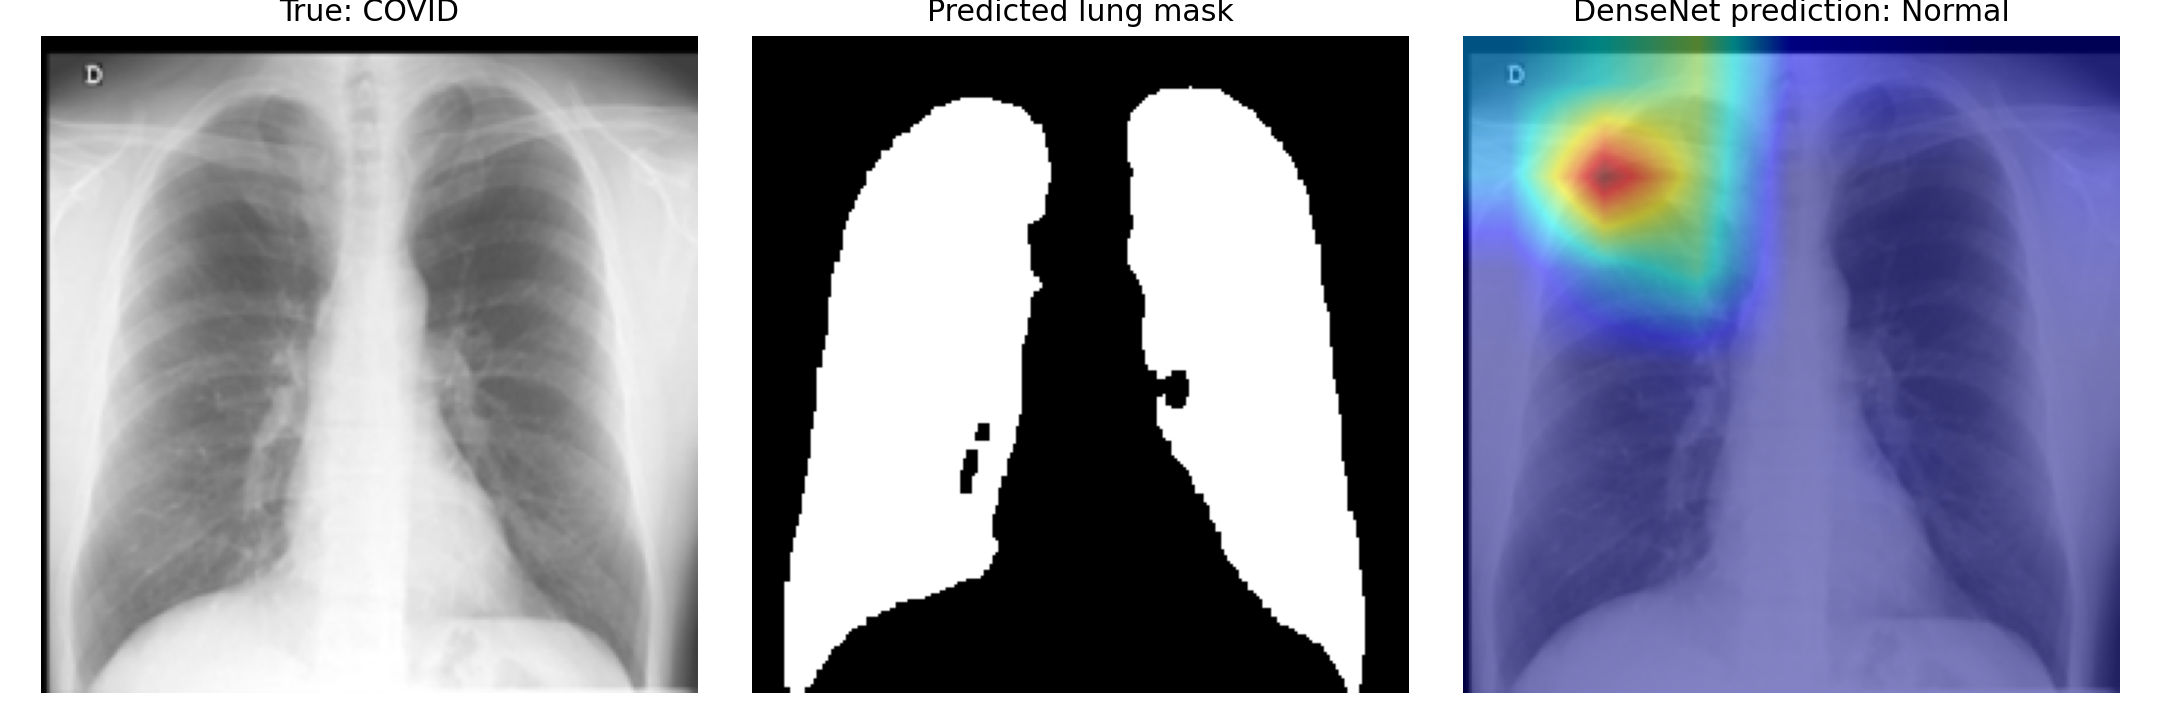


### Archived figure: gradcam_0_6

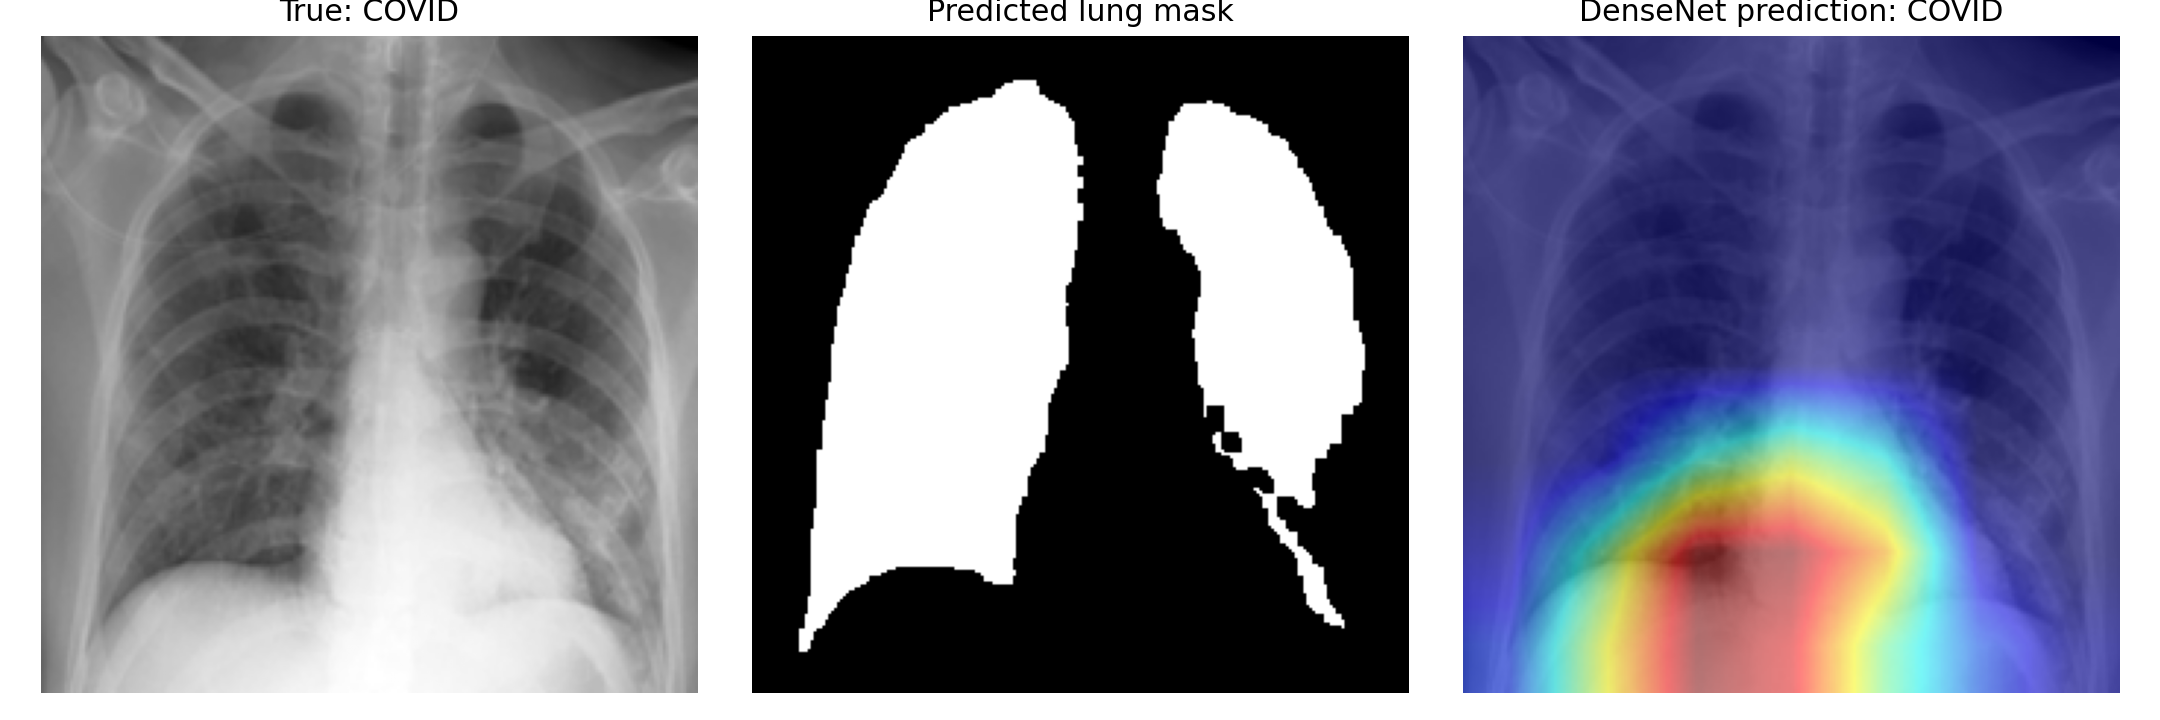


### Archived figure: gradcam_1_0

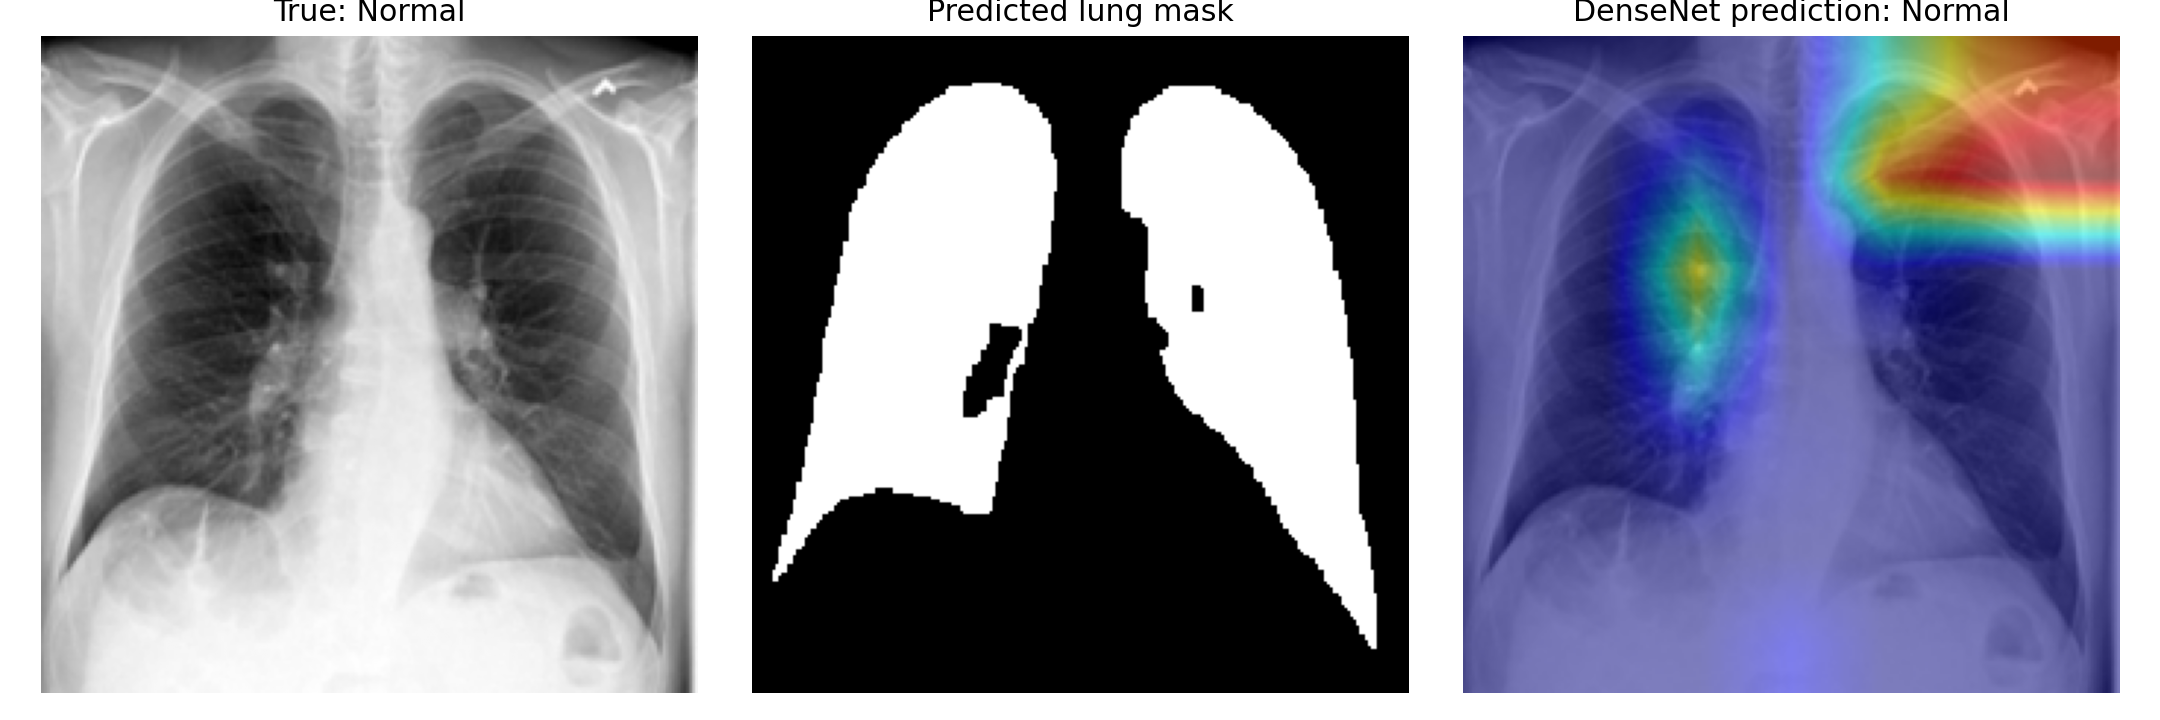


### Archived figure: gradcam_1_33

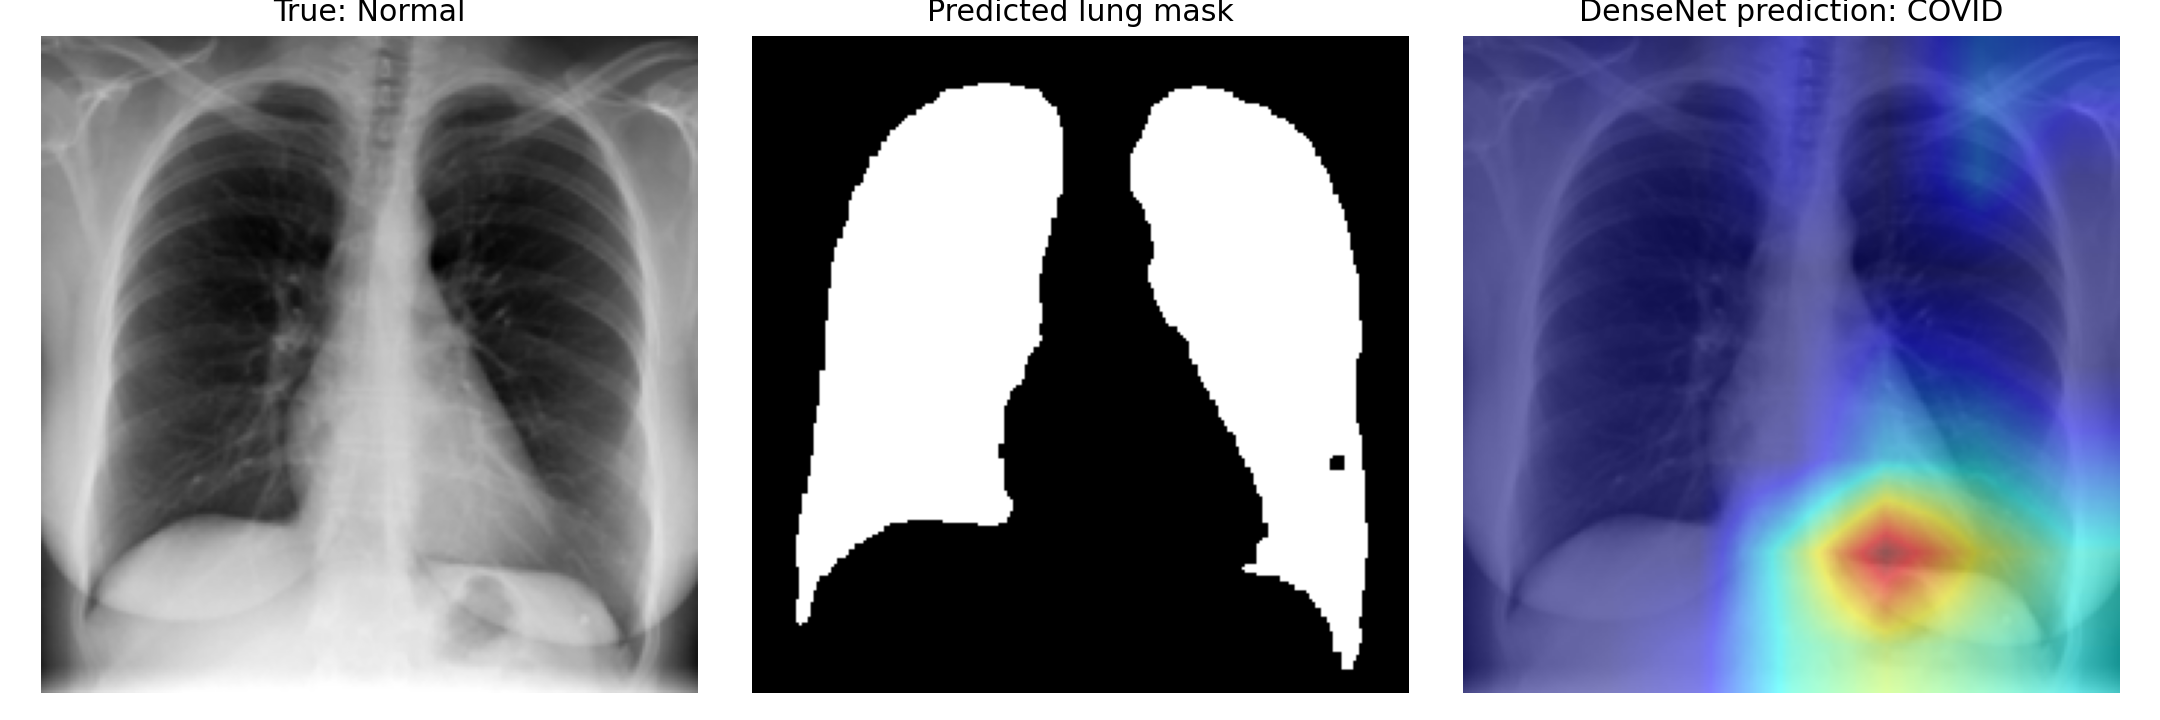


### Archived figure: gradcam_2_2

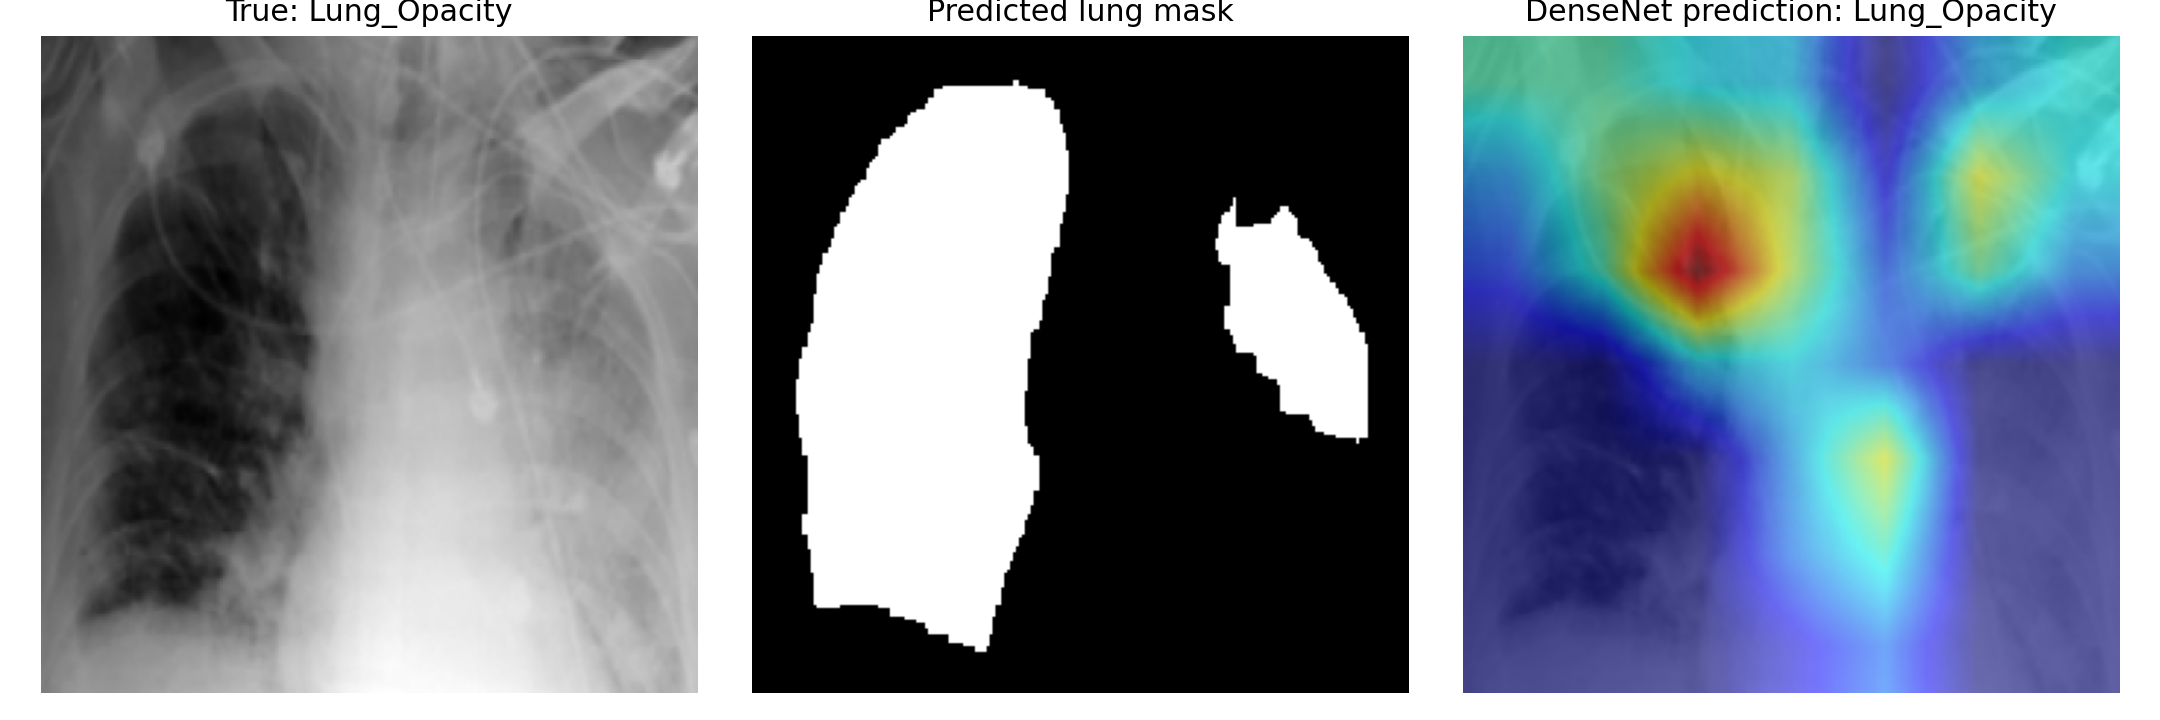


### Archived figure: gradcam_2_60

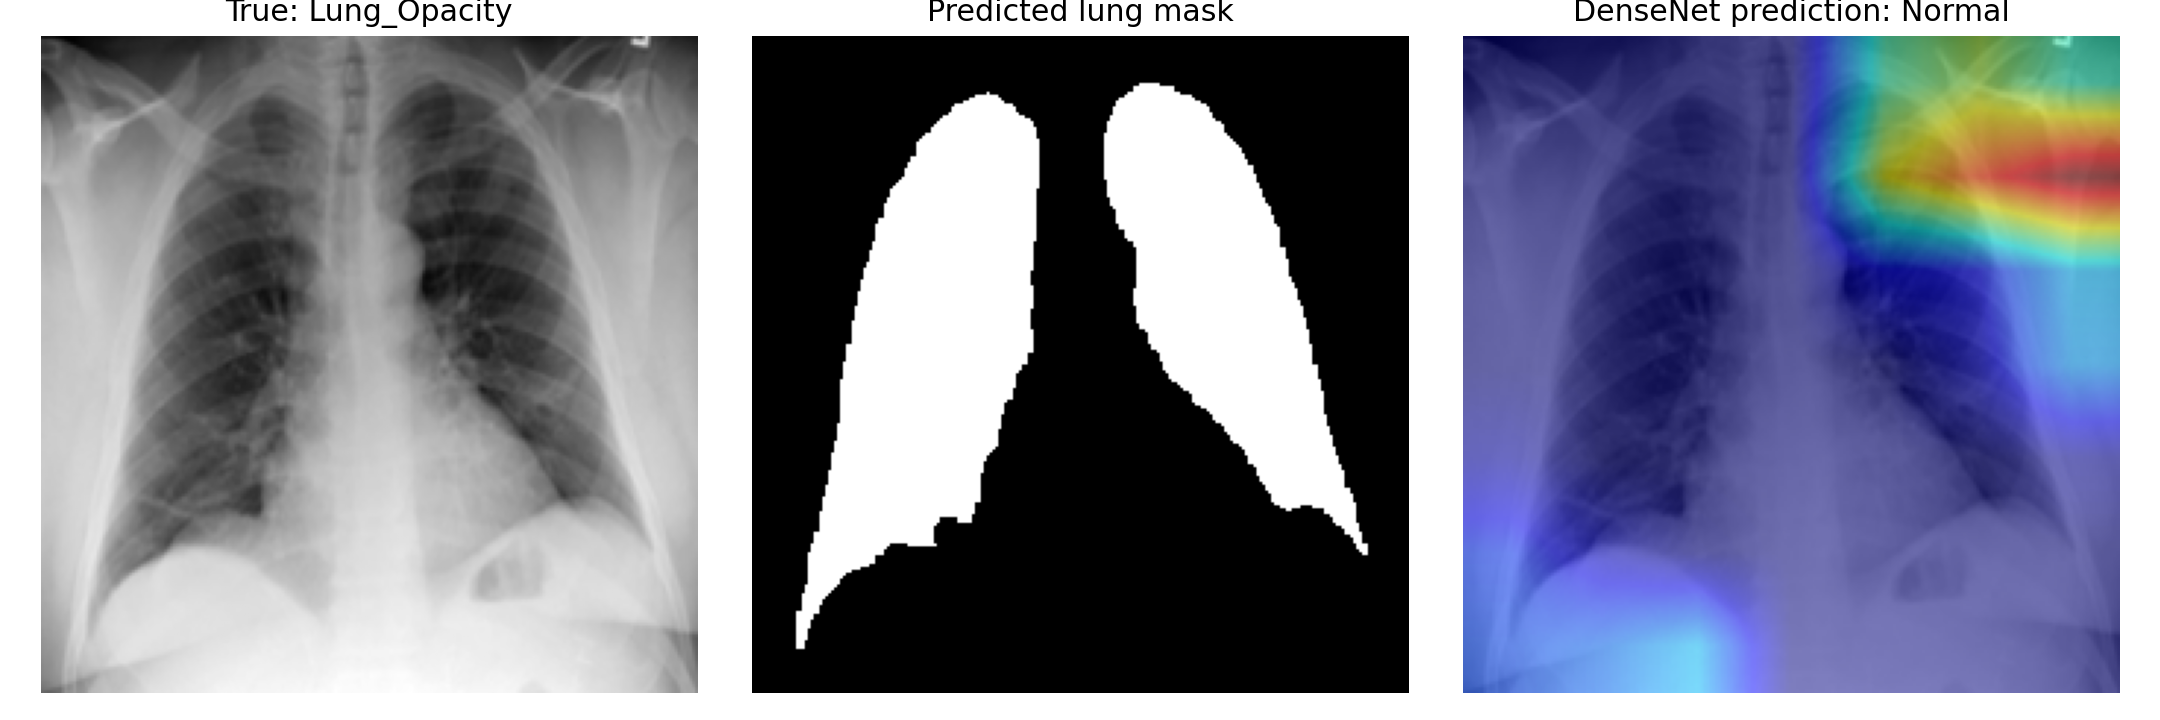


### Archived figure: gradcam_3_1342

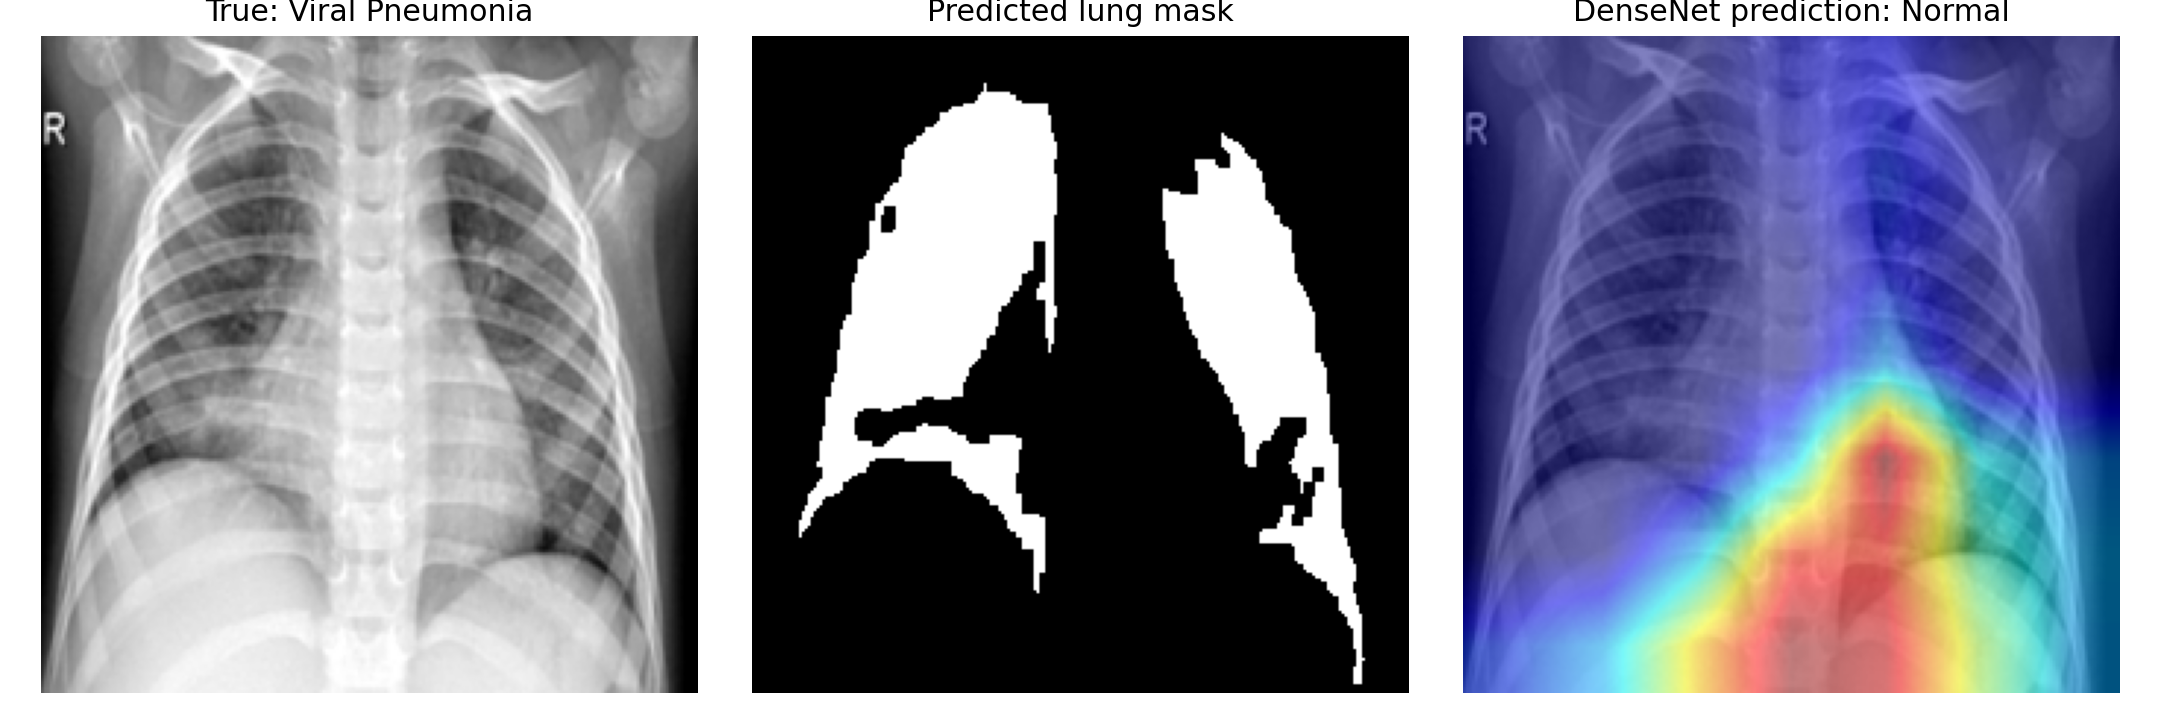


### Archived figure: gradcam_3_38

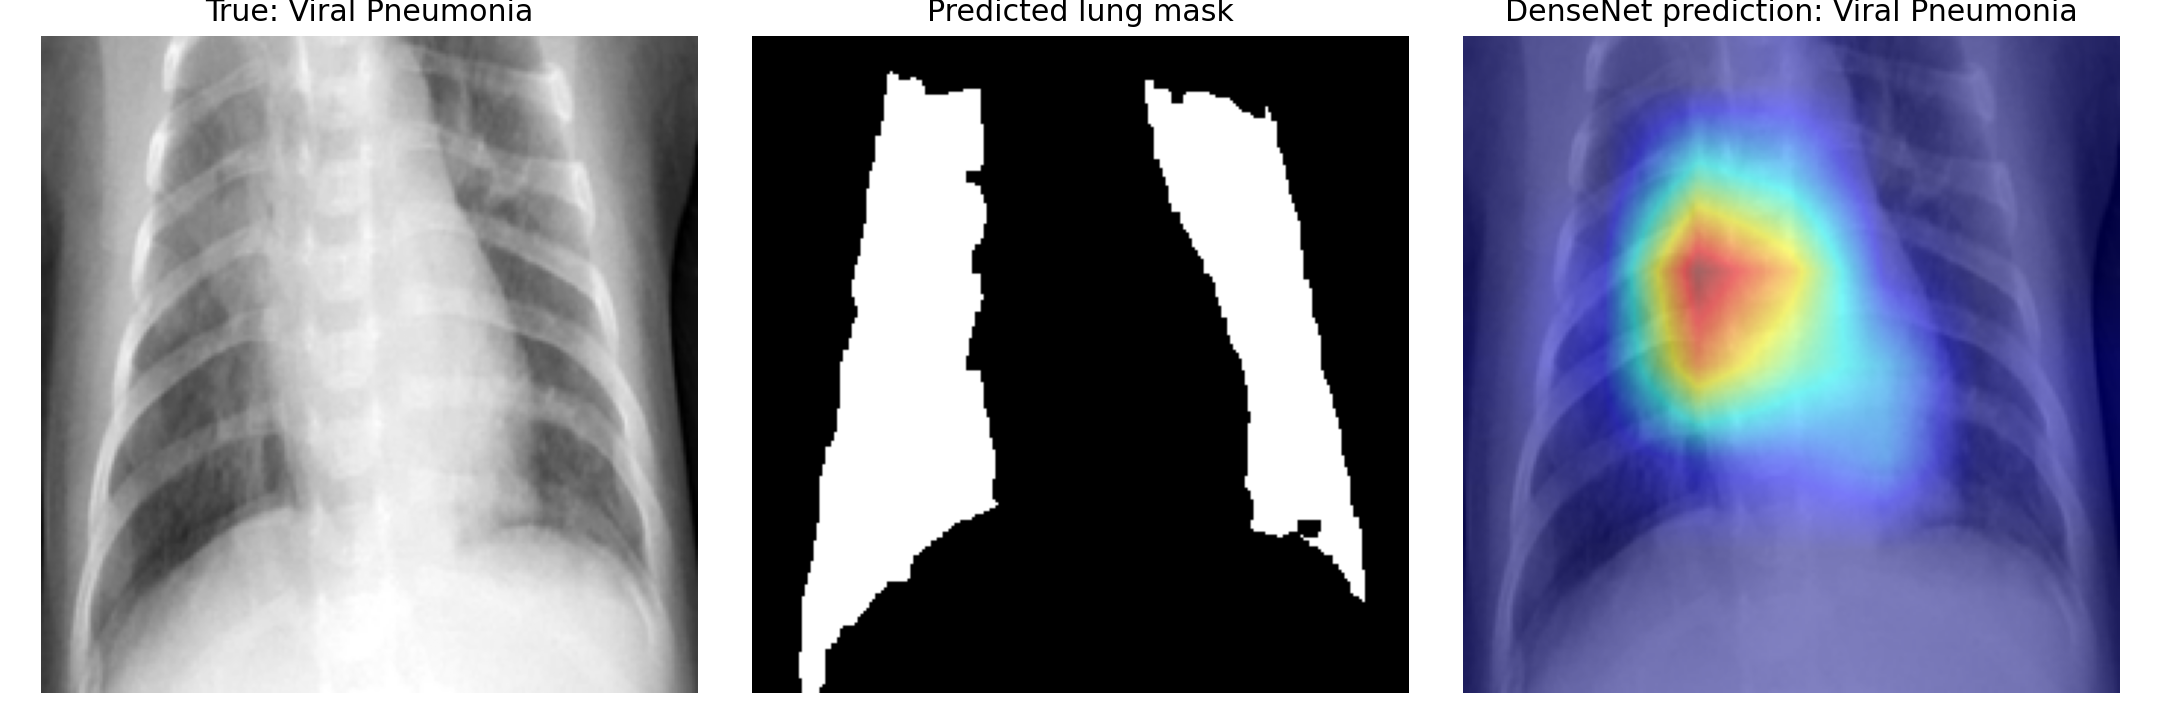


### Archived figure: measured_ablations

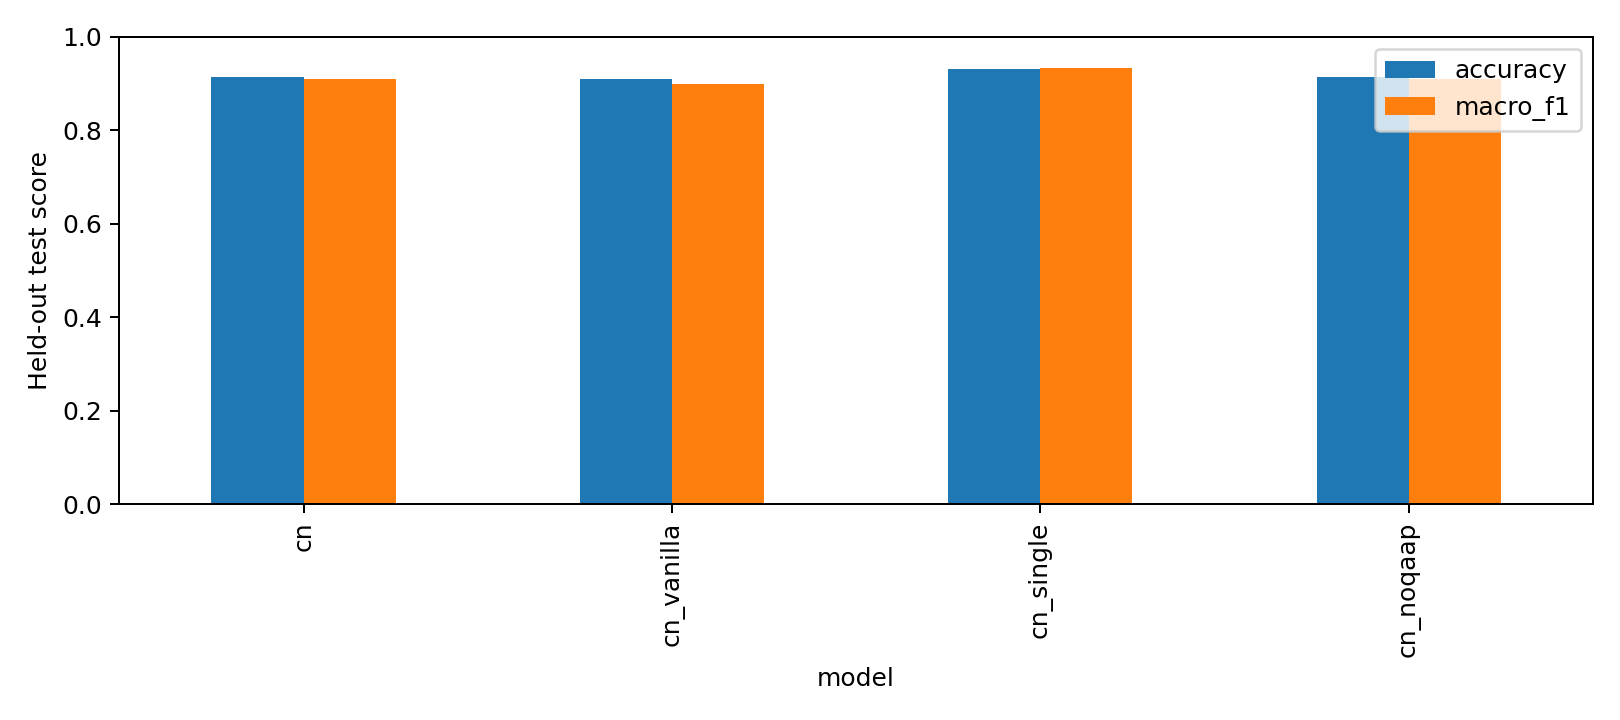


### Archived figure: reliability

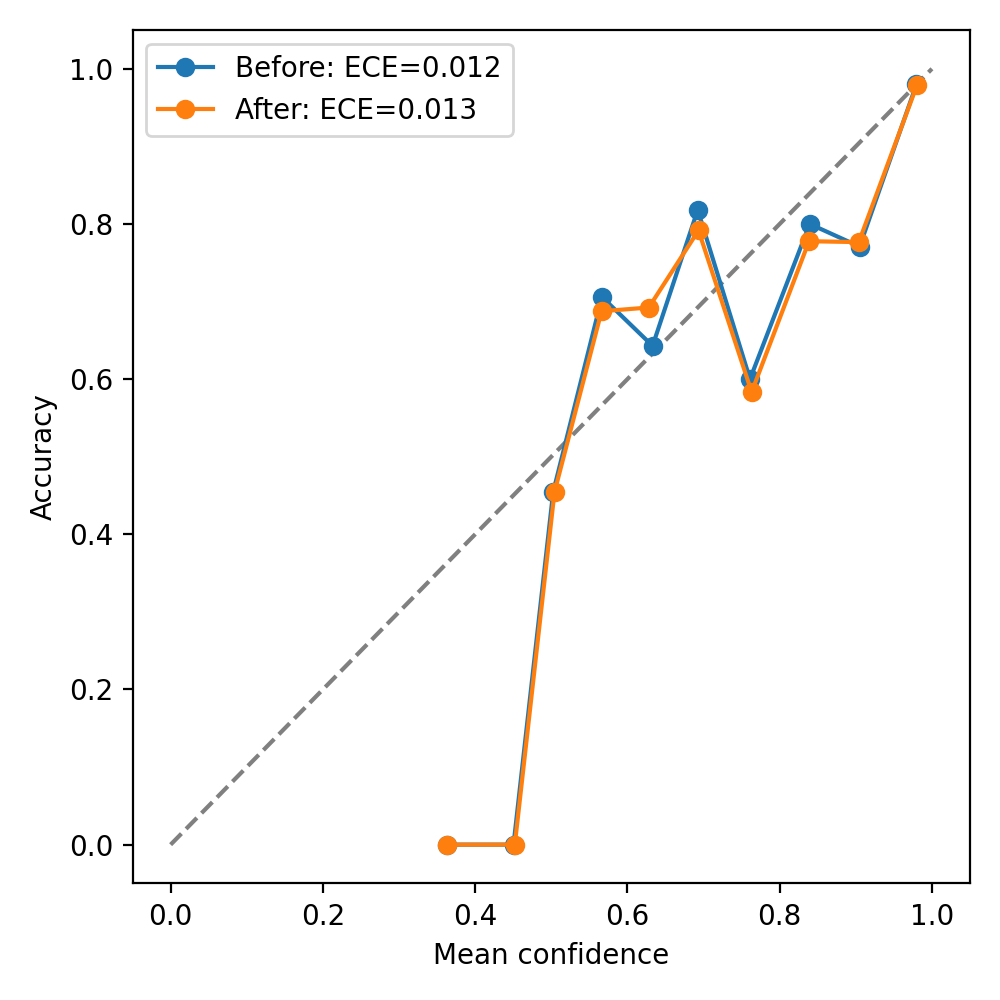


### Archived figure: tb_confusion

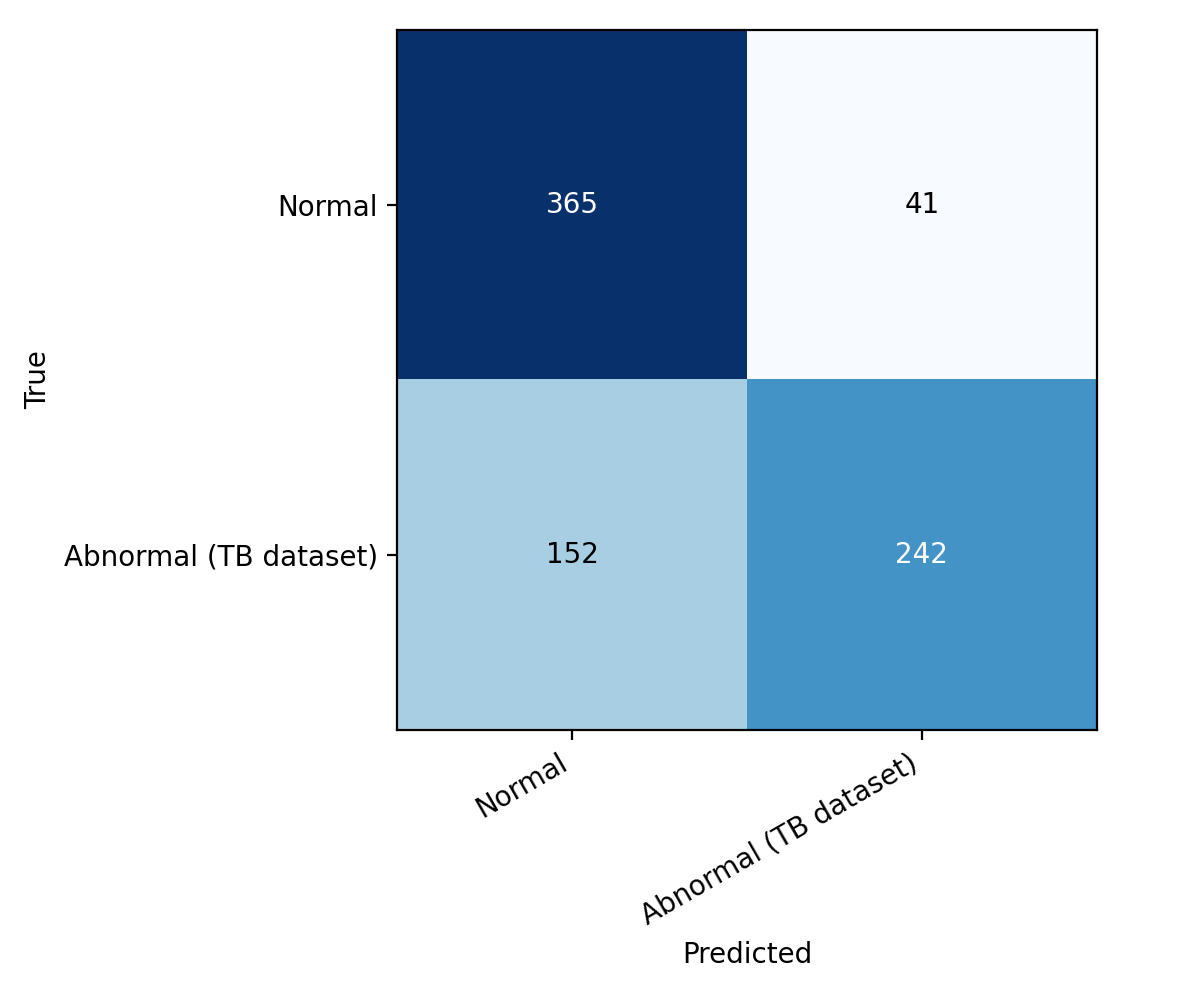


### Archived figure: test_confusion

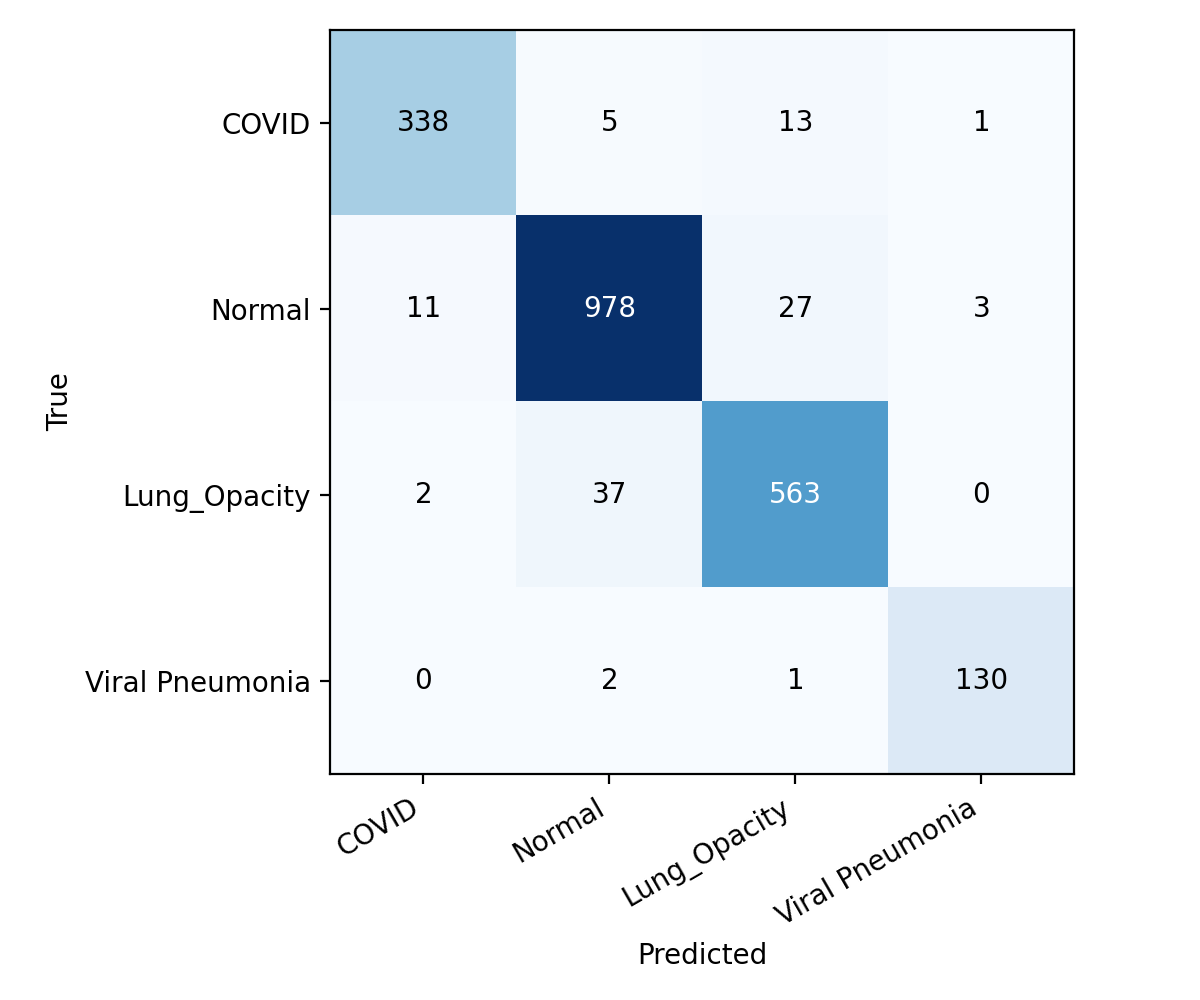


## Remaining publication checks

Dataset licences, redistribution permissions, ethics statements, patient independence,
and clinical applicability require the authors' assessment. This notebook documents
the implemented experiment; it does not establish that all scientific targets were met.
Manufacturer analysis is unavailable, the latency target failed, and original-baseline
accuracy non-inferiority has not been measured. Preserve these limitations in reporting.
